# Uploading and Downloading Large Files: Presigned URLs, Multipart, Chunked and Resumable Uploads

> **Who is this for:** Anyone building an app where users upload files (PDFs for a RAG app, audio for transcription, datasets, model weights) and who has hit errors like `413 Request Entity Too Large`, timeouts, or a server that runs out of memory.
>
> **What you will learn:**
> - Why big uploads break: a request-size limit, a timeout and a memory limit at **every hop** between the browser and storage
> - The core pattern: the browser uploads **straight to object storage** with a **presigned URL**, so the file never passes through your 10 MB-limited API
> - **Multipart upload** for big files (the 100 MB example): parts, ETags, parallel workers, retries, resume after a refresh, checksums and cleanup
> - Browser code (File.slice, fetch, XHR progress, pause and resume), bucket CORS, and libraries (Uppy, tus-js-client)
> - Resumable protocols: **tus**, Google Cloud Storage resumable uploads, Azure block blobs, Cloudflare R2, Supabase Storage
> - Streaming when you must proxy, upload security, large downloads with **Range** requests, and AI-specific cases
>
> **Prerequisites:** [Deployment concepts](01_deployment_concepts.ipynb), [Serverless deployment](03_serverless_deployment.ipynb), [AI SaaS end to end](06_deploying_an_ai_saas_application_end_to_end.ipynb), [Concurrency and async](../23_Software_Engineering/05_concurrency_and_async.ipynb), [Computer networks for AI apps](../23_Software_Engineering/07_computer_networks_for_ai_apps.ipynb)
>
> **Time needed:** 60-90 minutes to read, under 1 minute to run
>
> **Runs on:** CPU, no API key, no internet. Every cloud service is replaced by a small in-memory Python stand-in. Real SDK, CLI and JavaScript code is shown in markdown blocks only.

**A note on numbers.** Every limit in this notebook was read from the provider's official documentation on **2026-11-13**. Limits change. Before you design around a number, open the linked page and check it again.

**How this notebook relates to others in the repo**

| Topic | Where it is covered in depth |
|---|---|
| Multi-tenancy, per-tenant prefixes, quotas, a first look at upload tokens | [16_Deployment/06_deploying_an_ai_saas_application_end_to_end.ipynb](06_deploying_an_ai_saas_application_end_to_end.ipynb) |
| Queues, retries, dead-letter queues, idempotency | [16_Deployment/message_queues/01_message_queues.ipynb](message_queues/01_message_queues.ipynb) |
| Document ingestion at scale (parse, OCR, chunk, embed) | [22_ML_System_Design/11_rag_at_scale_100_million_pdfs_low_latency.ipynb](../22_ML_System_Design/11_rag_at_scale_100_million_pdfs_low_latency.ipynb) |
| Serverless limits and cold starts | [16_Deployment/03_serverless_deployment.ipynb](03_serverless_deployment.ipynb) |
| S3, GCS and Blob Storage basics | [18_Cloud/12_cloud_building_blocks_compared_aws_gcp_azure.ipynb](../18_Cloud/12_cloud_building_blocks_compared_aws_gcp_azure.ipynb) |
| Web app security in general | [23_Software_Engineering/08_security_for_ai_applications.ipynb](../23_Software_Engineering/08_security_for_ai_applications.ipynb) |

### Table of contents
1. Why uploads break
2. The core pattern: direct-to-storage upload with presigned URLs
3. Multipart upload for big files (runnable: mock object store, 30 MiB upload with failures and resume)
4. The browser side (JavaScript)
5. Resumable protocols: tus, GCS, Azure, R2, Supabase (runnable: mini tus server and client)
6. Server-side streaming when you must proxy (runnable: size cap, hashing, local chunked HTTP demo)
7. Security for uploads (runnable: magic-byte sniffing, safe keys, scanning pipeline)
8. Large downloads (runnable: Range requests, resumable and parallel download, zip on the fly)
9. AI-specific cases: datasets, model weights, document ingestion, long audio
10. Cloud cheat sheet, how to try it for real, recap, interview questions, further reading

## 0. Setup

Only the Python standard library, numpy, pandas and matplotlib. A few size constants help us be exact: **MiB** (mebibyte) is 1024 x 1024 bytes, **MB** (megabyte) is 1,000,000 bytes. Cloud docs mix both, so we keep them apart.

In [1]:
import base64, hashlib, hmac, io, json, math, queue, random, re, threading, time, uuid, zlib, zipfile
import urllib.parse
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
rng = np.random.default_rng(SEED)
CHECKED = "2026-11-13"        # date the limits below were read from official docs

KiB, MiB, GiB, TiB = 1024, 1024**2, 1024**3, 1024**4   # binary units (powers of 1024)
KB, MB, GB = 1000, 1000**2, 1000**3                   # decimal units (powers of 1000)

def human(n):
    # Show a byte count in a readable way, using binary units.
    for unit, size in (("TiB", TiB), ("GiB", GiB), ("MiB", MiB), ("KiB", KiB)):
        if n >= size:
            return f"{n / size:.1f} {unit}"
    return f"{n} B"

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 180)
print("numpy", np.__version__, "| pandas", pd.__version__, "| limits checked on", CHECKED)

numpy 2.5.4 | pandas 3.1.1 | limits checked on 2026-11-13


## 1. Why uploads break

**What it is.** An upload is one HTTP request whose **body** (the bytes after the headers) is the file. Between the user's browser and the place the file is finally stored, that request passes through several **hops**: machines or services that receive it and pass it on. Each hop has its own rules.

**Simple analogy.** Sending a big sofa through a building. The front door, the lift, the corridor and the flat door each have a maximum size. The sofa only arrives if it fits through **every** one. And if any doorman gets bored waiting (a timeout), he shuts the door.

**How it works.** A typical path for a "naive" upload, where the API receives the file and then saves it:

```mermaid
flowchart LR
    B["Browser<br/>(file in memory?)"] --> CDN["CDN / edge proxy<br/>body limit"]
    CDN --> LB["Load balancer<br/>header limits, idle timeout"]
    LB --> GW["API gateway<br/>10 MB payload, 29-30 s"]
    GW --> FN["Serverless function<br/>6 MB sync payload"]
    FN --> APP["App server / reverse proxy<br/>nginx default 1 MB"]
    APP --> S3[("Object storage<br/>5 GB single PUT")]
```

Five things go wrong:

| Problem | What happens | Typical error |
|---|---|---|
| **Body-size limit** at some hop | The hop refuses the request | `413 Request Entity Too Large` (or `413 Payload Too Large`) |
| **Timeout** | A slow upload takes longer than a hop is willing to wait | `504 Gateway Timeout`, connection reset |
| **Memory** | A server reads the whole file into RAM; 20 users uploading 500 MB each need 10 GB | Out-of-memory, the process is killed |
| **Unreliable networks** | Mobile or hotel Wi-Fi drops after 80 MB; a single request must start again from zero | User gives up |
| **Cost of proxying** | Every byte passes through your compute: you pay for CPU time, memory and network twice | Big bill, slow API for everyone else |

The fix for all five is the same idea: **do not send the file through your API.** Your API only hands out permission; the bytes go straight to storage, in pieces when they are big.

### 1.1 Typical limits per hop (checked 2026-11-13, always check the docs)

These are default limits from the official pages listed in Further reading. Some can be raised, many cannot.

In [2]:
limits = pd.DataFrame([
    # hop, product, request-body limit, other limit worth knowing
    ("Browser",            "Any browser",                      "No fixed HTTP body limit",            "Reading a whole file into memory costs RAM; File.slice() is lazy"),
    ("CDN / edge",         "Amazon CloudFront",                "64 GB request body",                  "50 GB max cacheable GET response"),
    ("CDN / edge",         "Cloudflare proxy (by zone plan)",  "100 MB Free/Pro, 200 MB Business, up to 5 GB Enterprise", "Over the limit: 413"),
    ("Load balancer",      "AWS Application Load Balancer",    "No body limit listed",                "Headers: 64 KB total; Lambda target: 1 MB request and response"),
    ("API gateway",        "Amazon API Gateway REST API",      "10 MB payload (not adjustable)",      "Integration timeout up to 29 s by default"),
    ("API gateway",        "Amazon API Gateway HTTP API",      "10 MB payload (not adjustable)",      "Max integration timeout 30 s"),
    ("Serverless",         "AWS Lambda",                       "6 MB sync request and response",      "200 MB streamed response; 1 MB async"),
    ("Serverless",         "Vercel Functions",                 "4.5 MB request or response body",     "413 FUNCTION_PAYLOAD_TOO_LARGE; default duration 300 s"),
    ("Serverless",         "Netlify Functions",                "6 MB buffered (binary is base64: about 4.5 MB)", "60 s synchronous"),
    ("Serverless",         "Cloudflare Workers",               "Same as the zone plan above",         ""),
    ("Containers",         "Google Cloud Run",                 "32 MiB with an HTTP/1 server",        "No limit with an HTTP/2 server; 60 min request timeout"),
    ("Serverless",         "Azure Functions",                  "210 MB request",                      "HTTP response within 230 s (load balancer idle timeout)"),
    ("Reverse proxy",      "nginx client_max_body_size",       "1 MB default (1m)",                   "413 when exceeded; 0 disables the check"),
    ("Storage, one PUT",   "Amazon S3 PutObject",              "5 GB",                                "Multipart: 10,000 parts of 5 MiB-5 GiB, object up to 48.8 TiB"),
    ("Storage, one PUT",   "Azure Put Blob",                   "5,000 MiB",                           "Put Block: 4,000 MiB per block, 50,000 blocks"),
    ("Storage, one PUT",   "Cloudflare R2",                    "5 GiB single part",                   "Multipart like S3; object about 5 TiB"),
    ("Storage",            "Google Cloud Storage",             "Object up to 5 TiB",                  "Resumable session lasts up to a week"),
], columns=["hop", "product", "request body limit", "other limit"])
print(f"Default limits, checked {CHECKED}. Re-check before you rely on any of them.")
limits

Default limits, checked 2026-11-13. Re-check before you rely on any of them.


,hop,product,request body limit,other limit
0,Browser,Any browser,No fixed HTTP body limit,Reading a whole file into memory costs RAM; File.slice() is lazy
1,CDN / edge,Amazon CloudFront,64 GB request body,50 GB max cacheable GET response
2,CDN / edge,Cloudflare proxy (by zone plan),"100 MB Free/Pro, 200 MB Business, up to 5 GB Enterprise",Over the limit: 413
3,Load balancer,AWS Application Load Balancer,No body limit listed,Headers: 64 KB total; Lambda target: 1 MB request and response
4,API gateway,Amazon API Gateway REST API,10 MB payload (not adjustable),Integration timeout up to 29 s by default
5,API gateway,Amazon API Gateway HTTP API,10 MB payload (not adjustable),Max integration timeout 30 s
6,Serverless,AWS Lambda,6 MB sync request and response,200 MB streamed response; 1 MB async
7,Serverless,Vercel Functions,4.5 MB request or response body,413 FUNCTION_PAYLOAD_TOO_LARGE; default duration 300 s
8,Serverless,Netlify Functions,6 MB buffered (binary is base64: about 4.5 MB),60 s synchronous
9,Serverless,Cloudflare Workers,Same as the zone plan above,


**The owner's example.** A user wants to upload a **100 MB** PDF scan. Your API sits behind API Gateway (10 MB) and Lambda (6 MB). The small code below walks the request along each path and reports the first hop that refuses it.

In [3]:
def first_blocker(path, size):
    # path: list of (hop name, max body bytes or None for "no fixed limit", limit as the docs write it)
    for hop, limit, label in path:
        if limit is not None and size > limit:
            return f"413 at {hop} (limit {label})"
    return "arrives in storage"

through_api = [("Browser", None, ""), ("CloudFront", 64 * GB, "64 GB"), ("API Gateway", 10 * MB, "10 MB"),
               ("Lambda (sync)", 6 * MB, "6 MB"), ("S3 single PUT", 5 * GB, "5 GB")]
direct      = [("Browser", None, ""), ("S3 presigned PUT", 5 * GB, "5 GB")]
direct_mpu  = [("Browser", None, ""), ("S3 UploadPart", 5 * GiB, "5 GiB")]   # each part is its own request

for label, size in [("2 MB", 2 * MB), ("8 MB", 8 * MB), ("100 MiB", 100 * MiB), ("7 GB", 7 * GB)]:
    part = min(size, 8 * MiB)
    print(f"{label:>7} | via API: {first_blocker(through_api, size):33} "
          f"| direct PUT: {first_blocker(direct, size):35} "
          f"| multipart, 8 MiB parts: {first_blocker(direct_mpu, part)}")

   2 MB | via API: arrives in storage                | direct PUT: arrives in storage                  | multipart, 8 MiB parts: arrives in storage
   8 MB | via API: 413 at Lambda (sync) (limit 6 MB) | direct PUT: arrives in storage                  | multipart, 8 MiB parts: arrives in storage
100 MiB | via API: 413 at API Gateway (limit 10 MB)  | direct PUT: arrives in storage                  | multipart, 8 MiB parts: arrives in storage
   7 GB | via API: 413 at API Gateway (limit 10 MB)  | direct PUT: 413 at S3 presigned PUT (limit 5 GB) | multipart, 8 MiB parts: arrives in storage


**Timeouts matter as much as size.** Even if the size fits, a slow connection can make one request last longer than a hop allows. The plot shows how long one 100 MiB request takes at common upload speeds, against the 29-30 s API Gateway integration timeout. (Speeds are illustrative.)

   5 Mbit/s ->  167.8 s for one 100 MiB request; one 8 MiB part takes  13.4 s
  10 Mbit/s ->   83.9 s for one 100 MiB request; one 8 MiB part takes   6.7 s
  20 Mbit/s ->   41.9 s for one 100 MiB request; one 8 MiB part takes   3.4 s
  50 Mbit/s ->   16.8 s for one 100 MiB request; one 8 MiB part takes   1.3 s
 100 Mbit/s ->    8.4 s for one 100 MiB request; one 8 MiB part takes   0.7 s


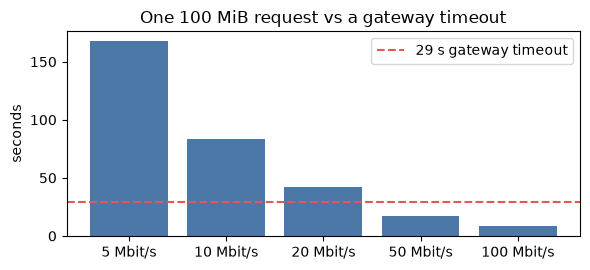

In [4]:
speeds_mbit = [5, 10, 20, 50, 100]                     # upload bandwidth in megabits per second
secs = [100 * MiB * 8 / (s * 1e6) for s in speeds_mbit]   # bytes -> bits, divided by bits per second
for s, t in zip(speeds_mbit, secs):
    print(f"{s:>4} Mbit/s -> {t:6.1f} s for one 100 MiB request; one 8 MiB part takes {8*MiB*8/(s*1e6):5.1f} s")

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.bar([f"{s} Mbit/s" for s in speeds_mbit], secs, color="#4C78A8")
ax.axhline(29, color="#E45756", linestyle="--", label="29 s gateway timeout")
ax.set_ylabel("seconds"); ax.set_title("One 100 MiB request vs a gateway timeout")
ax.legend(); plt.tight_layout(); plt.show()

**Memory: buffering vs streaming.** If a server reads the whole body into memory before saving it, memory grows with file size times the number of users uploading at once. If it streams (reads a small chunk, passes it on, forgets it), memory stays flat.

In [5]:
rows = []
for users in (1, 10, 50):
    for size in (100 * MiB, 1 * GiB):
        rows.append({"concurrent uploads": users, "file size": human(size),
                     "buffer whole file": human(users * size),
                     "stream 64 KiB chunks": human(users * 64 * KiB),
                     "direct to storage": "0 B on your server"})
pd.DataFrame(rows)

,concurrent uploads,file size,buffer whole file,stream 64 KiB chunks,direct to storage
0,1,100.0 MiB,100.0 MiB,64.0 KiB,0 B on your server
1,1,1.0 GiB,1.0 GiB,64.0 KiB,0 B on your server
2,10,100.0 MiB,1000.0 MiB,640.0 KiB,0 B on your server
3,10,1.0 GiB,10.0 GiB,640.0 KiB,0 B on your server
4,50,100.0 MiB,4.9 GiB,3.1 MiB,0 B on your server
5,50,1.0 GiB,50.0 GiB,3.1 MiB,0 B on your server


**Best practices: working within limits**
- Write down the body limit, timeout and memory limit of **every hop** you own. The smallest one is your real limit.
- Keep request bodies through your API **small** (JSON metadata only). Send file bytes straight to storage.
- Keep each request **short in time**: split big files into parts so that one part finishes well inside any timeout.
- Never read a whole upload into memory on a server. Stream, or better, do not receive it at all.
- When you must accept bodies through nginx or a proxy, set `client_max_body_size` (or equivalent) on purpose, not by accident.

## 2. The core pattern: direct-to-storage upload

**What it is.** A **presigned URL** is a normal storage URL with a time-limited signature in its query string. Anyone holding it can do exactly one thing (for example "PUT this object key") until it expires, without having cloud credentials. Your API creates it; the browser uses it.

**Simple analogy.** A valet ticket. The hotel desk (your API) checks who you are and writes a ticket that says "may park one car in bay 42 until 6 pm". The car (the file) goes straight to the car park (storage). The desk never touches the car.

**How it works.**

```mermaid
sequenceDiagram
    autonumber
    participant B as Browser
    participant A as Your API (10 MB limit)
    participant S as Object storage (S3 / GCS / Blob / R2)
    participant Q as Event + queue
    participant W as Worker
    B->>A: POST /uploads {name, size, type}  (tiny JSON)
    A->>A: check auth, size, type, quota; make a unique key
    A-->>B: presigned URL (or presigned POST + conditions), expires in 15 min
    B->>S: PUT file bytes directly (never through the API)
    S-->>B: 200 OK + ETag
    S->>Q: "object created" event
    Q->>W: message with bucket + key
    W->>W: scan, validate, parse / thumbnail / embed
    W->>A: mark file "ready" (or "rejected")
    B->>A: GET /files/{id} -> status ready
```

**Why the file never hits the 10 MB limit:** the only requests that go through API Gateway are steps 1 and 9, a few hundred bytes of JSON each. Step 4 goes from the browser to the storage service's own endpoint, which accepts up to 5 GB in one PUT on S3, and much more with multipart.

**Presigned PUT vs presigned POST**

| | Presigned PUT URL | Presigned POST (form + policy) |
|---|---|---|
| What the browser sends | `PUT` with the raw bytes as the body | `POST` multipart/form-data with fields + file |
| Can the server cap the size? | Partly: you can sign the `Content-Length` / `Content-Type` headers on some SDKs | Yes: `content-length-range` condition is enforced by storage |
| Key prefix rules | Exact key only | `starts-with` conditions allowed |
| Works with multipart | Yes (one presigned URL per part) | No, single request only (max 5 GB on S3) |
| Available on | S3, GCS (signed URL), Azure (SAS URL), R2 | S3, GCS (POST policy) |

**When to use it:** almost always, for any file bigger than a few MB, or any app on serverless.
**When not to:** tiny files (avatars of a few KB can go through the API), or when storage must not be reachable from the client network at all (then stream through a proxy, section 6).

### 2.1 Runnable: a presigned URL signer and verifier

Real clouds use AWS Signature Version 4, Google V4 signing, or Azure SAS. All of them follow the same idea: **HMAC** (a hash keyed with a secret) over the method, path, and expiry. Our stand-in uses HMAC-SHA256. The secret stays on the server; the signature proves the server approved this exact request.

In [6]:
SECRET = b"server-only-secret"            # stand-in for cloud credentials; never sent to the browser
BASE = "https://storage.mock"

def _canonical(method, path, params):
    # Everything the signature protects: method + path + all query params except the signature.
    return "\n".join([method, path, urllib.parse.urlencode(sorted(params.items()))])

def presign(method, bucket, key, expires_in, now, **extra):
    params = {k: str(v) for k, v in extra.items()}
    params["X-Expires"] = str(int(now + expires_in))
    path = f"/{bucket}/{key}"
    params["X-Signature"] = hmac.new(SECRET, _canonical(method, path, params).encode(), hashlib.sha256).hexdigest()
    return f"{BASE}{path}?" + urllib.parse.urlencode(sorted(params.items()))

def verify(method, url, now):
    # Returns (ok, params or error message). Storage runs this on every request.
    u = urllib.parse.urlsplit(url)
    params = dict(urllib.parse.parse_qsl(u.query))
    sig = params.pop("X-Signature", "")
    expected = hmac.new(SECRET, _canonical(method, u.path, params).encode(), hashlib.sha256).hexdigest()
    if not hmac.compare_digest(sig, expected):          # constant-time compare
        return False, "403 SignatureDoesNotMatch"
    if now > int(params["X-Expires"]):
        return False, "403 Request has expired"
    return True, params

now = 1_800_000_000                                     # a fixed clock keeps the demo repeatable
url = presign("PUT", "uploads", "tenants/t1/u/abc123", expires_in=900, now=now)
print("URL:", url[:110], "...")
print("PUT now          ->", verify("PUT", url, now)[0])
print("GET with PUT URL ->", verify("GET", url, now))
print("tampered key     ->", verify("PUT", url.replace("abc123", "other"), now))
print("after 16 minutes ->", verify("PUT", url, now + 16 * 60))

URL: https://storage.mock/uploads/tenants/t1/u/abc123?X-Expires=1800000900&X-Signature=158403bf155a178b72d96a90b676 ...
PUT now          -> True
GET with PUT URL -> (False, '403 SignatureDoesNotMatch')
tampered key     -> (False, '403 SignatureDoesNotMatch')
after 16 minutes -> (False, '403 Request has expired')


### 2.2 Runnable: presigned POST with conditions

With presigned POST, the server signs a **policy**: a small JSON document listing conditions. Storage checks every condition before it accepts the file, so a user cannot upload a 2 GB file when you allowed 25 MB, even if they edit the form.

In [7]:
def make_post_policy(key_prefix, max_bytes, content_type, expires_in, now):
    policy = {"expiration": int(now + expires_in),
              "conditions": [["starts-with", "$key", key_prefix],
                             ["content-length-range", 1, max_bytes],
                             ["eq", "$Content-Type", content_type]]}
    encoded = base64.b64encode(json.dumps(policy).encode()).decode()
    sig = hmac.new(SECRET, encoded.encode(), hashlib.sha256).hexdigest()
    return {"url": f"{BASE}/uploads", "fields": {"policy": encoded, "signature": sig}}

def storage_accepts_post(fields, form_key, content_type, file_size, now):
    # What storage does when the browser POSTs the form.
    sig = hmac.new(SECRET, fields["policy"].encode(), hashlib.sha256).hexdigest()
    if not hmac.compare_digest(sig, fields["signature"]):
        return "403 bad signature"
    policy = json.loads(base64.b64decode(fields["policy"]))
    if now > policy["expiration"]:
        return "403 policy expired"
    for cond in policy["conditions"]:
        if cond[0] == "starts-with" and not form_key.startswith(cond[2]):
            return f"403 key must start with {cond[2]}"
        if cond[0] == "content-length-range" and not (cond[1] <= file_size <= cond[2]):
            return f"400 EntityTooLarge/TooSmall (allowed {cond[1]}-{cond[2]} bytes)"
        if cond[0] == "eq" and content_type != cond[2]:
            return f"403 Content-Type must be {cond[2]}"
    return "204 accepted"

form = make_post_policy("tenants/t1/", max_bytes=25 * MB, content_type="application/pdf", expires_in=600, now=now)
print("2 MB PDF            ->", storage_accepts_post(form["fields"], "tenants/t1/a.pdf", "application/pdf", 2 * MB, now))
print("50 MB PDF           ->", storage_accepts_post(form["fields"], "tenants/t1/a.pdf", "application/pdf", 50 * MB, now))
print("other tenant prefix ->", storage_accepts_post(form["fields"], "tenants/t2/a.pdf", "application/pdf", 2 * MB, now))
print("HTML instead of PDF ->", storage_accepts_post(form["fields"], "tenants/t1/a.pdf", "text/html", 2 * MB, now))

2 MB PDF            -> 204 accepted
50 MB PDF           -> 400 EntityTooLarge/TooSmall (allowed 1-25000000 bytes)
other tenant prefix -> 403 key must start with tenants/t1/
HTML instead of PDF -> 403 Content-Type must be application/pdf


What the real calls look like (not run here):

```python
# boto3 (AWS SDK for Python)
s3 = boto3.client("s3", config=Config(signature_version="s3v4"))
put_url = s3.generate_presigned_url("put_object",
            Params={"Bucket": "uploads", "Key": key, "ContentType": "application/pdf"}, ExpiresIn=900)
post = s3.generate_presigned_post("uploads", key,
            Fields={"Content-Type": "application/pdf"},
            Conditions=[["content-length-range", 1, 25_000_000], {"Content-Type": "application/pdf"}],
            ExpiresIn=600)        # returns {"url": ..., "fields": {...}} for an HTML form
```

Expiry limits: S3 presigned URLs made with SigV4 can last up to 7 days (console: up to 12 hours), and stop working earlier if the temporary credentials that signed them expire. GCS V4 signed URLs: up to 7 days. Azure user delegation SAS: the delegation key is valid up to 7 days. Use **minutes**, not days, for uploads.

**Best practices: direct-to-storage**
- The API decides **everything** before signing: who the user is, max size, allowed types, quota, and the object key. The browser chooses nothing important.
- Short expiry (5-15 minutes for an upload URL). Sign one URL per object; never sign a "write anything" URL.
- Keep the bucket **private** (block public access). Uploads land in a "pending" or "quarantine" area until a worker approves them.
- Mark a file **ready** only after the storage event arrives and processing succeeds, not when the browser says "done".
- Configure **CORS** on the bucket so only your web origins can PUT (section 4).

## 3. Multipart upload for big files

**What it is.** **Multipart upload** splits one object into numbered **parts**. Each part is uploaded as its own small request. When all parts are in, one final call asks storage to join them into a single object. S3, GCS (XML API), R2 and other S3-compatible stores work this way; Azure has the same idea under the name "block blob".

**Simple analogy.** Moving house with numbered boxes. Several friends carry boxes at the same time. If one box is dropped, only that box is carried again. At the end you check the list "boxes 1 to 13, all here", and the flat is complete.

**How it works (the 100 MB example).** File = 100 MiB, part size = 8 MiB, so 100 / 8 = 12.5, rounded up to **13 parts**: twelve parts of 8 MiB and a last part of 4 MiB. Each part request is 8 MiB, well under a 10 MB limit, and it goes to storage, not to your API anyway.

```mermaid
sequenceDiagram
    autonumber
    participant B as Browser
    participant A as Your API
    participant S as S3
    B->>A: POST /uploads {name, size=100 MiB, type}
    A->>S: CreateMultipartUpload(key)
    S-->>A: UploadId
    A-->>B: UploadId, key, part size 8 MiB, 13 presigned UploadPart URLs
    par up to 4 parts at a time
        B->>S: PUT part 1 (8 MiB)
        S-->>B: ETag 1
    and
        B->>S: PUT part 2 (8 MiB)
        S-->>B: ETag 2
    end
    Note over B,S: retry a failed part only; keep {partNumber: ETag}
    B->>A: POST /uploads/{id}/complete [{1, ETag1}, ... {13, ETag13}]
    A->>S: CompleteMultipartUpload(parts)
    S-->>A: final ETag "...-13"
    S->>A: object-created event (via queue) -> worker -> status ready
```

**The rules storage enforces (S3, checked 2026-11-13; GCS XML API and R2 are the same):**

| Rule | Value |
|---|---|
| Part numbers | 1 to 10,000 |
| Part size | 5 MiB to 5 GiB; the **last** part may be smaller |
| Max parts | 10,000 |
| Max object | 48.8 TiB on S3 (5 TiB on GCS, about 5 TiB on R2) |
| Part ETag | Returned in the `ETag` response header of each UploadPart; you must send it back in Complete |
| Final ETag | Not the MD5 of the file. For S3 it is commonly the MD5 of the joined part MD5s plus `-<number of parts>` (an implementation detail: do not use it as a content hash) |
| R2 extra rule | All parts except the last must be the **same** size |
| Unfinished uploads | Parts are stored (and billed) until you Complete or Abort |

**When to use it:** files above roughly 100 MB (the S3 docs' own suggestion), anything over 5 GB (required), any upload on a flaky network, or when you want parallel speed.
**When not to:** small files, where one presigned PUT is simpler and cheaper (fewer requests).

### 3.1 Runnable: a mock object store with S3-like multipart rules

The class below imitates the five S3 calls: `CreateMultipartUpload`, `UploadPart`, `ListParts`, `CompleteMultipartUpload` and `AbortMultipartUpload`. It checks the presigned URL on every part, enforces part-size rules, returns MD5 ETags, verifies an optional CRC32 checksum per part, and emits an "object created" event when an upload completes. It is a teaching stand-in, not a real S3.

In [8]:
class StorageError(Exception):
    def __init__(self, status, code):
        super().__init__(f"{status} {code}")
        self.status, self.code = status, code

def crc32_b64(data):
    # S3 sends CRC32 checksums as base64 of the 4-byte big-endian value.
    return base64.b64encode(zlib.crc32(data).to_bytes(4, "big")).decode()

class MockObjectStore:
    MIN_PART, MAX_PART, MAX_PARTS, MAX_PUT = 5 * MiB, 5 * GiB, 10_000, 5 * GB

    def __init__(self):
        self.objects = {}      # key -> {"data", "etag", "checksum"}
        self.uploads = {}      # upload_id -> {"key", "parts": {n: (etag, bytes, crc)}, "initiated"}
        self.events = []       # stand-in for S3 -> EventBridge / SQS notifications
        self.lock = threading.Lock()

    def create_multipart_upload(self, key, now):
        upload_id = uuid.uuid4().hex
        with self.lock:
            self.uploads[upload_id] = {"key": key, "parts": {}, "initiated": now}
        return upload_id

    def upload_part(self, url, body, checksum_crc32=None, now=None):
        ok, params = verify("PUT", url, now if now is not None else time.time())
        if not ok:
            raise StorageError(403, params)
        upload_id, n = params["uploadId"], int(params["partNumber"])
        if upload_id not in self.uploads:
            raise StorageError(404, "NoSuchUpload")
        if not 1 <= n <= self.MAX_PARTS:
            raise StorageError(400, "InvalidArgument: partNumber")
        if len(body) > self.MAX_PART:
            raise StorageError(400, "EntityTooLarge")
        crc = crc32_b64(body)
        if checksum_crc32 is not None and checksum_crc32 != crc:
            raise StorageError(400, "BadDigest")         # bytes changed on the way
        etag = '"' + hashlib.md5(body).hexdigest() + '"'
        with self.lock:                                   # re-uploading a part number replaces it
            self.uploads[upload_id]["parts"][n] = (etag, bytes(body), crc)
        return etag

    def list_parts(self, upload_id):
        if upload_id not in self.uploads:
            raise StorageError(404, "NoSuchUpload")
        parts = self.uploads[upload_id]["parts"]
        return [{"PartNumber": n, "ETag": parts[n][0], "Size": len(parts[n][1])} for n in sorted(parts)]

    def complete_multipart_upload(self, upload_id, parts):
        up = self.uploads.get(upload_id)
        if up is None:
            raise StorageError(404, "NoSuchUpload")
        numbers = [p["PartNumber"] for p in parts]
        if numbers != sorted(set(numbers)):
            raise StorageError(400, "InvalidPartOrder")
        for i, p in enumerate(parts):
            stored = up["parts"].get(p["PartNumber"])
            if stored is None or stored[0] != p["ETag"]:
                raise StorageError(400, f"InvalidPart {p['PartNumber']}")
            if i < len(parts) - 1 and len(stored[1]) < self.MIN_PART:
                raise StorageError(400, f"EntityTooSmall part {p['PartNumber']}")
        chosen = [up["parts"][n] for n in numbers]
        data = b"".join(c[1] for c in chosen)
        md5s = b"".join(bytes.fromhex(c[0].strip('"')) for c in chosen)
        etag = f'"{hashlib.md5(md5s).hexdigest()}-{len(chosen)}"'           # S3-style multipart ETag
        crcs = b"".join(base64.b64decode(c[2]) for c in chosen)
        composite = f"{crc32_b64(crcs)}-{len(chosen)}"                      # "checksum of checksums"
        with self.lock:
            self.objects[up["key"]] = {"data": data, "etag": etag, "checksum_crc32": composite}
            del self.uploads[upload_id]                                     # parts are gone after Complete
            self.events.append({"type": "ObjectCreated", "key": up["key"], "size": len(data)})
        return {"ETag": etag, "ChecksumCRC32": composite}

    def abort_multipart_upload(self, upload_id):
        with self.lock:
            self.uploads.pop(upload_id, None)

    def put_object(self, url, body, now=None):
        ok, params = verify("PUT", url, now if now is not None else time.time())
        if not ok:
            raise StorageError(403, params)
        if len(body) > self.MAX_PUT:
            raise StorageError(400, "EntityTooLarge")
        key = urllib.parse.urlsplit(url).path.split("/", 2)[2]
        self.objects[key] = {"data": bytes(body), "etag": '"' + hashlib.md5(body).hexdigest() + '"'}
        self.events.append({"type": "ObjectCreated", "key": key, "size": len(body)})

    def stored_bytes_in_unfinished_uploads(self):
        return sum(len(p[1]) for u in self.uploads.values() for p in u["parts"].values())

    def lifecycle_abort_incomplete(self, now, days_after_initiation):
        # Stand-in for the AbortIncompleteMultipartUpload lifecycle rule.
        old = [uid for uid, u in self.uploads.items() if now - u["initiated"] > days_after_initiation * 86400]
        for uid in old:
            self.abort_multipart_upload(uid)
        return old

store = MockObjectStore()
print("mock store ready; min part", human(store.MIN_PART), "| max parts", store.MAX_PARTS)

mock store ready; min part 5.0 MiB | max parts 10000


### 3.2 Runnable: the API behind a 10 MB gateway

Now the **API**. It sits behind a gateway stand-in that rejects any request body over **10 MB** with `413`, just like API Gateway. The API never receives file bytes in the good path: it creates the multipart upload, signs part URLs, lists parts for resume, and completes. It also has a naive `POST /files` route that tries to receive the whole file, so we can watch it fail.

In [9]:
def choose_part_size(size, preferred=8 * MiB, min_part=5 * MiB, max_part=5 * GiB, max_parts=10_000):
    # Pick a part size that respects the store's rules; round up to a whole MiB.
    part = max(preferred, min_part, math.ceil(size / max_parts))
    part = math.ceil(part / MiB) * MiB
    if part > max_part:
        raise ValueError("file too large for multipart limits")
    return part, math.ceil(size / part)

class UploadAPI:
    MAX_FILE = 2 * GiB
    ALLOWED = {"application/pdf", "audio/wav", "application/octet-stream"}
    URL_TTL = 15 * 60

    def __init__(self, store):
        self.store, self.files = store, {}      # files: our database table of upload records

    def create(self, user, body):
        if user is None:
            return 401, {"error": "login required"}
        if body["size"] > self.MAX_FILE:
            return 400, {"error": f"max {human(self.MAX_FILE)}"}
        if body["content_type"] not in self.ALLOWED:
            return 415, {"error": "type not allowed"}
        part_size, count = choose_part_size(body["size"])
        key = f"tenants/{user['tenant']}/incoming/{uuid.uuid4().hex}"   # server-chosen key, never the filename
        upload_id = self.store.create_multipart_upload(key, now=time.time())
        self.files[upload_id] = {"key": key, "owner": user["id"], "status": "uploading",
                                 "display_name": body["filename"], "size": body["size"]}
        urls = [self._sign(key, upload_id, n) for n in range(1, count + 1)]
        return 200, {"upload_id": upload_id, "key": key, "part_size": part_size, "part_count": count, "part_urls": urls}

    def _sign(self, key, upload_id, n):
        return presign("PUT", "uploads", key, self.URL_TTL, time.time(), uploadId=upload_id, partNumber=n)

    def sign_part(self, user, upload_id, n):            # for URLs that expired during a long upload
        rec = self.files.get(upload_id)
        if rec is None or rec["owner"] != user["id"]:
            return 404, {"error": "no such upload"}
        return 200, {"url": self._sign(rec["key"], upload_id, n)}

    def list_parts(self, user, upload_id):
        rec = self.files.get(upload_id)
        if rec is None or rec["owner"] != user["id"]:
            return 404, {"error": "no such upload"}
        return 200, {"parts": self.store.list_parts(upload_id)}

    def complete(self, user, upload_id, body):
        rec = self.files.get(upload_id)
        if rec is None or rec["owner"] != user["id"]:
            return 404, {"error": "no such upload"}
        try:
            result = self.store.complete_multipart_upload(upload_id, body["parts"])
        except StorageError as e:
            return e.status, {"error": e.code}
        rec["status"] = "processing"                   # NOT ready yet: a worker must check it first
        return 200, {"etag": result["ETag"], "checksum_crc32": result["ChecksumCRC32"], "status": rec["status"]}

    def abort(self, user, upload_id):
        self.store.abort_multipart_upload(upload_id)
        self.files.pop(upload_id, None)
        return 204, {}

    def naive_upload(self, user, raw_bytes):           # what we are trying to avoid
        return 200, {"received": len(raw_bytes)}

class Gateway:
    LIMIT = 10 * MB                                    # like API Gateway's 10 MB payload limit

    def __init__(self, api):
        self.api, self.bytes_through = api, 0

    def call(self, method, path, user, json_body=None, raw=None):
        payload = raw if raw is not None else json.dumps(json_body or {}).encode()
        if len(payload) > self.LIMIT:
            return 413, {"error": f"Request Entity Too Large ({human(len(payload))} > 10 MB)"}
        self.bytes_through += len(payload)
        parts = path.strip("/").split("/")
        if method == "POST" and path == "/uploads":
            return self.api.create(user, json_body)
        if method == "POST" and path == "/files":
            return self.api.naive_upload(user, payload)
        upload_id = parts[1]
        if method == "GET" and parts[-1] == "parts":
            return self.api.list_parts(user, upload_id)
        if method == "POST" and parts[-1] == "sign":
            return self.api.sign_part(user, upload_id, json_body["part_number"])
        if method == "POST" and parts[-1] == "complete":
            return self.api.complete(user, upload_id, json_body)
        if method == "DELETE":
            return self.api.abort(user, upload_id)
        return 404, {"error": "no route"}

api = UploadAPI(store)
gateway = Gateway(api)
alice = {"id": "u-alice", "tenant": "t1"}

for size in (100 * MiB, 1 * GiB, 70 * GB, 1 * TiB):
    p, n = choose_part_size(size)
    print(f"{human(size):>9}: part size {human(p):>9} -> {n:>6} parts")

100.0 MiB: part size   8.0 MiB ->     13 parts
  1.0 GiB: part size   8.0 MiB ->    128 parts
 65.2 GiB: part size   8.0 MiB ->   8345 parts
  1.0 TiB: part size 105.0 MiB ->   9987 parts


**Step 1: the naive way fails.** We make a 30 MiB test file (we use 30 MiB instead of 100 MiB to keep memory and run time small; the logic is identical, and the part maths for 100 MiB is printed above and below). Sending it as one request body through the gateway gets `413`.

In [10]:
FILE_SIZE = 30 * MiB
data = rng.bytes(FILE_SIZE)                       # random bytes stand in for a real file
file_sha256 = hashlib.sha256(data).hexdigest()
print("test file:", human(len(data)), "| sha256", file_sha256[:16], "...")

status, body = gateway.call("POST", "/files", alice, raw=data)
print("naive POST /files ->", status, body)
print("100 MiB with 8 MiB parts would be", math.ceil(100 * MiB / (8 * MiB)), "parts; each part request is 8 MiB")

test file: 30.0 MiB | sha256 4846726420997789 ...
naive POST /files -> 413 {'error': 'Request Entity Too Large (30.0 MiB > 10 MB)'}
100 MiB with 8 MiB parts would be 13 parts; each part request is 8 MiB


**Step 2: the multipart client.** This is the Python stand-in for the browser code in section 4. It:
- asks the API for an upload (tiny JSON request),
- uploads parts in **parallel** with a pool of 4 workers (`concurrent.futures.ThreadPoolExecutor`),
- sends a CRC32 checksum with each part, so storage can reject corrupted bytes,
- retries a failed part with **exponential backoff plus jitter** (wait 10 ms, 20 ms, 40 ms... plus a little randomness, so many clients do not retry at the same moment),
- saves its progress in a `local_storage` dict (stand-in for the browser's `localStorage`), so it can resume after a refresh.

A `FlakyNetwork` drops about 25% of part requests at random to show the retries working.

In [11]:
class FlakyNetwork:
    def __init__(self, fail_rate, seed):
        self.fail_rate, self.rng, self.lock = fail_rate, random.Random(seed), threading.Lock()
        self.drops = 0

    def send(self, fn, *args, **kwargs):
        with self.lock:
            drop = self.rng.random() < self.fail_rate
            if drop:
                self.drops += 1
        if drop:
            raise ConnectionError("simulated network drop")
        return fn(*args, **kwargs)

def with_retries(fn, attempts=6, base=0.01):
    for attempt in range(attempts):
        try:
            return fn()
        except ConnectionError:
            if attempt == attempts - 1:
                raise
            time.sleep(base * 2 ** attempt + random.uniform(0, base))   # exponential backoff + jitter

local_storage = {}          # browser localStorage stand-in: survives a "refresh"

def upload_parts(info, data, todo, net, workers=4, log=print):
    # Upload the given part numbers in parallel; return {part_number: etag}.
    part_size, done, lock = info["part_size"], {}, threading.Lock()
    sent = [0]

    def one(n):
        chunk = data[(n - 1) * part_size: n * part_size]           # like File.slice(start, end)
        crc = crc32_b64(chunk)
        etag = with_retries(lambda: net.send(store.upload_part, info["part_urls"][n - 1], chunk, checksum_crc32=crc))
        with lock:
            done[n] = etag
            sent[0] += len(chunk)
            state = json.loads(local_storage[info["upload_id"]])
            state["etags"][str(n)] = etag
            local_storage[info["upload_id"]] = json.dumps(state)      # persist progress after each part
        log(f"  part {n:>2} ok ({human(len(chunk))}), progress {100 * sent[0] / len(data):5.1f}% of this run")
        return n

    with ThreadPoolExecutor(max_workers=workers) as pool:
        for f in as_completed([pool.submit(one, n) for n in todo]):
            f.result()
    return done

status, info = gateway.call("POST", "/uploads", alice,
                            json_body={"filename": "scan.pdf", "size": len(data), "content_type": "application/pdf"})
print("create ->", status, "| parts:", info["part_count"], "x", human(info["part_size"]),
      "| request body was", len(json.dumps({"filename": "scan.pdf", "size": len(data), "content_type": "application/pdf"})), "bytes")
local_storage[info["upload_id"]] = json.dumps({"key": info["key"], "size": len(data), "etags": {}})

create -> 200 | parts: 4 x 8.0 MiB | request body was 77 bytes


**Step 3: upload some parts, then the user refreshes the page.** We upload only parts 1 and 2 (and the network drops some requests on the way), then pretend the tab was reloaded: all in-memory state is gone except `local_storage`.

In [12]:
net = FlakyNetwork(fail_rate=0.25, seed=7)
t0 = time.time()
upload_parts(info, data, todo=[1, 2], net=net)
print(f"network drops so far: {net.drops} (each one was retried)")

# ---- "browser refresh": forget everything except local_storage ----
upload_id_saved = next(iter(local_storage))
del info
print("refresh! saved state:", {k: (v if k != "etags" else list(v)) for k, v in json.loads(local_storage[upload_id_saved]).items()})

  part  1 ok (8.0 MiB), progress  26.7% of this run


  part  2 ok (8.0 MiB), progress  53.3% of this run
network drops so far: 1 (each one was retried)
refresh! saved state: {'key': 'tenants/t1/incoming/a5063ebb46e8439dbeb891267b582127', 'size': 31457280, 'etags': ['1', '2']}


**Step 4: resume.** The new page finds the saved upload, asks the API which parts storage already has (`ListParts`), asks for fresh part URLs (the old ones may have expired), uploads only the missing parts, and completes.

A detail from the S3 docs: for the final Complete call, AWS recommends using the part list **you kept yourself** (part number and ETag from each upload response) rather than trusting `ListParts`. Here we compare both and only continue if they agree.

In [13]:
saved = json.loads(local_storage[upload_id_saved])
status, listed = gateway.call("GET", f"/uploads/{upload_id_saved}/parts", alice)
have = {p["PartNumber"]: p["ETag"] for p in listed["parts"]}
assert all(have[int(n)] == e for n, e in saved["etags"].items()), "local list and ListParts disagree"
part_size, count = choose_part_size(saved["size"])
missing = [n for n in range(1, count + 1) if n not in have]
print("storage already has parts", sorted(have), "| missing", missing)

# fresh URLs for the missing parts (signed on demand)
urls = [None] * count
for n in missing:
    urls[n - 1] = gateway.call("POST", f"/uploads/{upload_id_saved}/sign", alice, json_body={"part_number": n})[1]["url"]
info = {"upload_id": upload_id_saved, "part_size": part_size, "part_urls": urls}
upload_parts(info, data, todo=missing, net=net)

etags = json.loads(local_storage[upload_id_saved])["etags"]
parts = [{"PartNumber": int(n), "ETag": e} for n, e in sorted(etags.items(), key=lambda kv: int(kv[0]))]
status, result = gateway.call("POST", f"/uploads/{upload_id_saved}/complete", alice, json_body={"parts": parts})
print("complete ->", status, result)
print(f"total network drops: {net.drops} | elapsed {time.time() - t0:.2f} s")

storage already has parts [1, 2] | missing [3, 4]
  part  4 ok (6.0 MiB), progress  20.0% of this run
  part  3 ok (8.0 MiB), progress  46.7% of this run
complete -> 200 {'etag': '"12def560d1a88b2fd7d7970abb64ada0-4"', 'checksum_crc32': 'NPItqg==-4', 'status': 'processing'}
total network drops: 2 | elapsed 0.10 s


**Step 5: verify.** The joined object must have the same SHA-256 as the original file. We also recompute the S3-style multipart ETag by hand to show where the `-4` suffix comes from (30 MiB in 8 MiB parts = 4 parts), and check how many bytes went through the gateway.

In [14]:
obj = store.objects[api.files[upload_id_saved]["key"]]
print("sha256 matches original:", hashlib.sha256(obj["data"]).hexdigest() == file_sha256)

part_md5s = b"".join(hashlib.md5(data[i:i + part_size]).digest() for i in range(0, len(data), part_size))
print("final ETag:", obj["etag"], "| recomputed:", f'"{hashlib.md5(part_md5s).hexdigest()}-{count}"')
print("plain MD5 of the file (different!):", hashlib.md5(data).hexdigest())
print(f"bytes that passed through the 10 MB gateway: {gateway.bytes_through:,} (the file is {len(data):,})")
print("events waiting for a worker:", store.events)
_ = local_storage.pop(upload_id_saved)       # clean up the saved state once complete

sha256 matches original: True


final ETag: "12def560d1a88b2fd7d7970abb64ada0-4" | recomputed: "12def560d1a88b2fd7d7970abb64ada0-4"


plain MD5 of the file (different!): 5f91b72309a15ed31a088dbcc76fed45
bytes that passed through the 10 MB gateway: 394 (the file is 31,457,280)
events waiting for a worker: [{'type': 'ObjectCreated', 'key': 'tenants/t1/incoming/a5063ebb46e8439dbeb891267b582127', 'size': 31457280}]


**Step 6: the worker and the "ready" flag.** Storage emitted an `ObjectCreated` event. In production it goes to a queue (SQS, Pub/Sub, Service Bus) and a worker processes it. Only the worker marks the file `ready`. (Scanning and type checks come in section 7.)

In [15]:
def worker_drain(store, api):
    while store.events:
        ev = store.events.pop(0)
        rec = next(r for r in api.files.values() if r["key"] == ev["key"])
        # real work here: virus scan, magic-byte check, parse/OCR, thumbnails, embeddings...
        rec["status"] = "ready"
        print(f"worker: {ev['key']} ({human(ev['size'])}) -> status {rec['status']}")

worker_drain(store, api)

worker: tenants/t1/incoming/a5063ebb46e8439dbeb891267b582127 (30.0 MiB) -> status ready


**Step 7: abort and cleanup.** Users close tabs. Each abandoned multipart upload keeps its parts in storage, and you pay for them, but they do not show up as normal objects in a bucket listing. Two defences:
1. Call `AbortMultipartUpload` when the user cancels.
2. Add a bucket **lifecycle rule** that aborts any multipart upload not finished within N days (S3 `AbortIncompleteMultipartUpload` with `DaysAfterInitiation`; R2 aborts after 7 days by default; GCS has a lifecycle condition for this too; Azure garbage-collects uncommitted blocks after a week).

In [16]:
t_start = time.time()
abandoned = store.create_multipart_upload("tenants/t1/incoming/abandoned", now=t_start)
url1 = presign("PUT", "uploads", "tenants/t1/incoming/abandoned", 900, t_start, uploadId=abandoned, partNumber=1)
store.upload_part(url1, data[:5 * MiB], now=t_start)
print("hidden bytes in unfinished uploads:", human(store.stored_bytes_in_unfinished_uploads()))
print("sweep after 3 days ->", store.lifecycle_abort_incomplete(t_start + 3 * 86400, days_after_initiation=7))
print("sweep after 8 days ->", len(store.lifecycle_abort_incomplete(t_start + 8 * 86400, days_after_initiation=7)), "upload(s) aborted")
print("hidden bytes now:", human(store.stored_bytes_in_unfinished_uploads()))

# and a few rules the store enforces
try:
    store.complete_multipart_upload("nope", [])
except StorageError as e:
    print("complete unknown upload ->", e)

hidden bytes in unfinished uploads: 5.0 MiB
sweep after 3 days -> []
sweep after 8 days -> 1 upload(s) aborted
hidden bytes now: 0 B
complete unknown upload -> 404 NoSuchUpload


The real lifecycle rule (S3, JSON for `aws s3api put-bucket-lifecycle-configuration`):

```json
{"Rules": [{"ID": "abort-stale-multipart", "Status": "Enabled", "Filter": {"Prefix": ""},
            "AbortIncompleteMultipartUpload": {"DaysAfterInitiation": 7}}]}
```

**Checksums: per part and whole object.** S3 accepts a checksum with each part (`x-amz-checksum-crc32`, `-crc32c`, `-crc64nvme`, `-sha1`, `-sha256`, and newer ones such as XXHash) and checks it on arrival; a mismatch fails the part with `BadDigest`. For the whole object you can choose a **composite** checksum (a checksum of the part checksums, shown above as `...-4`) or a **full-object** checksum (CRC64NVME is the default algorithm in current AWS SDKs). As of late 2026 the S3 docs list CRC64NVME, CRC32, CRC32C, SHA-1, SHA-256, MD5, XXHash64, XXHash3, XXHash128 and SHA-512. If you need a hash of the content for your own records (de-duplication, "same file?" checks), compute SHA-256 yourself; do not use the ETag.

**Choosing a part size**

| File | Sensible part size | Parts | Why |
|---|---|---|---|
| 100 MiB PDF | 8 MiB | 13 | Small parts retry cheaply on mobile |
| 5 GiB video | 16-64 MiB | 80-320 | Fewer requests, still quick to retry |
| 70 GB model checkpoint | 64-128 MiB | 500-1,100 | High bandwidth servers; fewer requests |
| 1 TiB dataset shard | at least 105 MiB | under 10,000 | Must satisfy the 10,000-part limit |

Rule of thumb: `part_size = max(5 MiB, preferred, ceil(size / 10,000))`. Smaller parts mean cheaper retries and finer progress but more requests (each request costs a little). Concurrency of 4-6 parts at a time is common in browsers; servers often use 8-32.

**Best practices: multipart**
- Let the API create the upload and sign part URLs; sign **on demand** (or in batches) for very large files instead of returning 10,000 URLs at once.
- Keep your own `{partNumber: ETag}` list; persist it (localStorage, IndexedDB, or your database) so a refresh can resume.
- Retry only the failed part, with exponential backoff and jitter, and a maximum number of attempts.
- Send a checksum per part. Verify a whole-file hash at the end if correctness matters.
- Always configure the abort-incomplete lifecycle rule. Call Abort when the user cancels.
- Mark the file ready from the **storage event + worker**, not from the client's "complete" call.

## 4. The browser side (JavaScript)

**What it is.** The browser code that does what our Python client did: slice the file, upload parts in parallel, show progress, retry, pause and resume.

**Simple analogy.** A cashier counting a big pile of coins in stacks of 100: she never holds the whole pile in her hands, only one stack at a time.

**How it works.** Five browser features do the heavy lifting:

| Browser API | What it does here |
|---|---|
| `File` / `Blob.slice(start, end)` | Returns a **view** of part of the file without reading it into memory |
| `fetch(url, {method: "PUT", body: blob})` | Sends one part; the browser streams the blob from disk |
| `XMLHttpRequest` + `xhr.upload.onprogress` | Gives byte-level **upload progress** (`loaded`, `total`); `fetch` has no upload progress event |
| `AbortController` | Cancels in-flight requests (pause / cancel button) |
| `localStorage` or IndexedDB | Remembers `uploadId`, key and finished ETags, so a refresh can resume |

Note: listeners on `xhr.upload` must be added **before** `send()`, and they make a cross-origin request "non-simple", so the browser sends a CORS preflight first.

```javascript
// upload.js - multipart upload straight to S3 with presigned part URLs (not run here)
const PART_SIZE = 8 * 1024 * 1024;           // 8 MiB
const CONCURRENCY = 4;

async function api(path, body) {              // tiny JSON calls to YOUR API (well under 10 MB)
  const r = await fetch(path, { method: body ? "POST" : "GET",
    headers: { "Content-Type": "application/json" }, body: body && JSON.stringify(body) });
  if (!r.ok) throw new Error(`${path}: ${r.status}`);
  return r.json();
}

function putPart(url, blob, onProgress, signal) {   // XHR for progress; resolves with the ETag
  return new Promise((resolve, reject) => {
    const xhr = new XMLHttpRequest();
    xhr.upload.onprogress = e => e.lengthComputable && onProgress(e.loaded);
    xhr.onload = () => xhr.status < 300 ? resolve(xhr.getResponseHeader("ETag"))
                                        : reject(new Error("HTTP " + xhr.status));
    xhr.onerror = () => reject(new Error("network"));
    signal.addEventListener("abort", () => xhr.abort());
    xhr.open("PUT", url);
    xhr.send(blob);
  });
}

async function withRetry(fn, attempts = 5) {
  for (let i = 0; ; i++) {
    try { return await fn(); }
    catch (e) { if (i >= attempts - 1) throw e;
                await new Promise(r => setTimeout(r, 500 * 2 ** i + Math.random() * 250)); }
  }
}

export async function uploadFile(file, { onProgress, signal }) {
  const saveKey = `upload:${file.name}:${file.size}:${file.lastModified}`;   // file "fingerprint"
  let state = JSON.parse(localStorage.getItem(saveKey) || "null");
  if (!state) {
    const info = await api("/uploads", { filename: file.name, size: file.size, content_type: file.type });
    state = { uploadId: info.upload_id, partSize: info.part_size, count: info.part_count, etags: {} };
    localStorage.setItem(saveKey, JSON.stringify(state));
  }
  const loaded = new Array(state.count).fill(0);
  const report = () => onProgress(loaded.reduce((a, b) => a + b, 0) / file.size);
  const todo = [...Array(state.count).keys()].map(i => i + 1).filter(n => !state.etags[n]);
  for (const n of Object.keys(state.etags)) loaded[n - 1] = Math.min(state.partSize, file.size - (n - 1) * state.partSize);

  async function worker() {                    // a simple pool: CONCURRENCY workers share one queue
    while (todo.length) {
      const n = todo.shift();
      const blob = file.slice((n - 1) * state.partSize, n * state.partSize);   // no copy, no RAM spike
      const etag = await withRetry(async () => {
        const { url } = await api(`/uploads/${state.uploadId}/sign`, { part_number: n }); // fresh URL each try
        return putPart(url, blob, b => { loaded[n - 1] = b; report(); }, signal);
      });
      state.etags[n] = etag;
      localStorage.setItem(saveKey, JSON.stringify(state));                   // resume point
    }
  }
  await Promise.all(Array.from({ length: CONCURRENCY }, worker));
  const parts = Object.entries(state.etags).map(([n, e]) => ({ PartNumber: +n, ETag: e }))
                      .sort((a, b) => a.PartNumber - b.PartNumber);
  const done = await api(`/uploads/${state.uploadId}/complete`, { parts });
  localStorage.removeItem(saveKey);
  return done;
}
// Pause = controller.abort(); Resume = call uploadFile(file) again: it skips parts with saved ETags.
```

For the browser to read the `ETag` header from S3's response, the bucket's **CORS** rules must expose it. Without `ExposeHeaders: ["ETag"]`, `getResponseHeader("ETag")` returns `null` and Complete fails.

```json
[{
  "AllowedOrigins": ["https://app.example.com"],
  "AllowedMethods": ["PUT", "POST", "GET"],
  "AllowedHeaders": ["content-type", "x-amz-checksum-crc32"],
  "ExposeHeaders": ["ETag"],
  "MaxAgeSeconds": 3600
}]
```

**Libraries so you do not write all of this yourself**

| Library | What it gives you | Notes (checked 2026-11-13) |
|---|---|---|
| **Uppy** with `@uppy/aws-s3` | UI (drag and drop, progress), S3 single PUT and multipart, retries, resume | Uses multipart for files over 100 MiB by default (`shouldUseMultipart`). Signing modes: your own endpoint signs each request, temporary credentials, or **Uppy Companion** (a small Node server that signs and also imports from URLs, Google Drive, Dropbox) |
| **tus-js-client** (and Uppy's tus plugin) | Resumable uploads to any **tus** server (tusd, Supabase Storage, many SaaS) | Stores the upload URL in localStorage and resumes with HEAD |
| **AWS SDK for JavaScript v3** `@aws-sdk/lib-storage` `Upload` | Multipart with concurrency (`queueSize`) and part size options | Needs credentials in the browser (for example from Cognito), so presigned URLs are usually simpler |
| Older "Evaporate-style" helpers | Browser-side S3 multipart with a signing endpoint | Mostly replaced by Uppy and the AWS SDK |

**Best practices: browser side**
- Use `File.slice()`; never `FileReader.readAsArrayBuffer()` on a whole large file.
- Use XHR (or summed per-part progress) for progress bars; show bytes and percent, not just a spinner.
- Limit concurrency (4-6 parts); more parallel requests rarely help a single user's uplink.
- Persist resume state keyed by a file fingerprint (name + size + lastModified).
- Expose `ETag` in bucket CORS and allow only your own origins.
- Warn before closing the tab while an upload runs (`beforeunload`).

## 5. Resumable upload protocols

**What it is.** A **resumable upload** lets a client continue an interrupted upload from the last byte the server received, instead of starting again. Multipart (section 3) is one way. The others below send the file as a **sequence** of chunks to one upload resource that remembers an **offset** (how many bytes it has).

**Simple analogy.** A bookmark in a long book. After an interruption you ask "what page was I on?" and carry on from there.

| Protocol | How you create it | How you send bytes | How you resume | Used by |
|---|---|---|---|---|
| **tus** (open protocol, v1.0.0) | `POST` with `Upload-Length` -> `201` + `Location` | `PATCH` with `Upload-Offset` and `Content-Type: application/offset+octet-stream` | `HEAD` returns `Upload-Offset` | tusd, Supabase Storage, Uppy, many apps |
| **GCS resumable upload** | `POST ...?uploadType=resumable` (or a signed URL with `x-goog-resumable: start`) -> **session URI** | `PUT` chunks with `Content-Range: bytes a-b/total`; reply `308 Resume Incomplete` + `Range` | `PUT` with `Content-Range: bytes */total` | Google Cloud Storage; session lasts up to a week; chunks must be multiples of 256 KiB (except the last) |
| **Azure block blob** | Nothing to create | `Put Block` with a base64 **block ID** (any order, in parallel) | `Get Block List` shows uncommitted blocks | Azure Blob Storage; up to 4,000 MiB per block and 50,000 blocks; commit with `Put Block List` |
| **S3 / R2 multipart** | `CreateMultipartUpload` -> UploadId | `UploadPart` (any order, in parallel) | `ListParts` | S3, R2, GCS XML API, MinIO |
| **Supabase Storage** | tus `POST` to `/storage/v1/upload/resumable` | tus `PATCH` in **6 MB** chunks (required) | tus `HEAD`; upload URL valid up to 24 hours | Supabase |

**Sequential vs parallel:** tus core and GCS resumable send chunks **in order** (one offset). Multipart and Azure blocks can go **in parallel**. tus has a `concatenation` extension for parallel parts.

### 5.1 Runnable: a mini tus server and client

The server keeps every byte it received, even from a request that broke halfway (that is the point of tus). The client creates an upload, sends 1 MiB `PATCH` chunks, and when the network drops mid-chunk it asks `HEAD` for the real offset and continues from there. This is an in-process stand-in: `handle()` takes a method, path, headers and body, like an HTTP server would.

In [17]:
class TusServer:
    VERSION = "1.0.0"

    def __init__(self, max_size):
        self.max_size, self.uploads = max_size, {}

    def handle(self, method, path, headers, body=b""):
        if method == "OPTIONS":
            return 204, {"Tus-Version": self.VERSION, "Tus-Extension": "creation,termination",
                         "Tus-Max-Size": str(self.max_size)}
        if headers.get("Tus-Resumable") != self.VERSION:
            return 412, {"Tus-Version": self.VERSION}                      # unsupported protocol version
        h = {"Tus-Resumable": self.VERSION}
        if method == "POST" and path == "/files":                          # creation extension
            length = int(headers["Upload-Length"])
            if length > self.max_size:
                return 413, h
            uid = uuid.uuid4().hex[:12]
            self.uploads[uid] = {"length": length, "data": bytearray(), "meta": headers.get("Upload-Metadata", "")}
            return 201, {**h, "Location": f"/files/{uid}"}
        uid = path.rsplit("/", 1)[-1]
        up = self.uploads.get(uid)
        if up is None:
            return 404, h
        if method == "HEAD":
            return 200, {**h, "Upload-Offset": str(len(up["data"])), "Upload-Length": str(up["length"]),
                         "Cache-Control": "no-store"}
        if method == "PATCH":
            if headers.get("Content-Type") != "application/offset+octet-stream":
                return 415, h
            if int(headers["Upload-Offset"]) != len(up["data"]):
                return 409, {**h, "Upload-Offset": str(len(up["data"]))}   # offset mismatch: nothing written
            if len(up["data"]) + len(body) > up["length"]:
                return 400, h
            up["data"] += body
            return 204, {**h, "Upload-Offset": str(len(up["data"]))}
        if method == "DELETE":                                             # termination extension
            del self.uploads[uid]
            return 204, h
        return 405, h

class DroppyLink:
    # Sometimes delivers only part of a PATCH body to the server, then fails on the client side.
    def __init__(self, server, drop_rate, seed):
        self.server, self.drop_rate, self.rng, self.drops = server, drop_rate, random.Random(seed), 0

    def request(self, method, path, headers, body=b""):
        if method == "PATCH" and body and self.rng.random() < self.drop_rate:
            self.drops += 1
            cut = self.rng.randrange(0, len(body))
            self.server.handle(method, path, headers, body[:cut])          # server keeps what arrived
            raise ConnectionError(f"dropped after {human(cut)}")
        return self.server.handle(method, path, headers, body)

def tus_upload(link, data, chunk=1 * MiB):
    base = {"Tus-Resumable": "1.0.0"}
    meta = "filename " + base64.b64encode(b"interview.wav").decode()
    status, h = link.request("POST", "/files", {**base, "Upload-Length": str(len(data)), "Upload-Metadata": meta})
    assert status == 201, status
    loc, offset = h["Location"], 0
    print("created", loc)
    while offset < len(data):
        try:
            status, h = link.request("PATCH", loc, {**base, "Upload-Offset": str(offset),
                                     "Content-Type": "application/offset+octet-stream"}, data[offset:offset + chunk])
            offset = int(h["Upload-Offset"])
        except ConnectionError as e:
            status, h = link.request("HEAD", loc, base)                     # where did we get to?
            print(f"  {e}; HEAD says offset = {human(int(h['Upload-Offset']))}, resuming")
            offset = int(h["Upload-Offset"])
    return loc

tus = TusServer(max_size=1 * GiB)
link = DroppyLink(tus, drop_rate=0.3, seed=3)
audio = data[:6 * MiB]                                   # reuse 6 MiB of our test bytes
loc = tus_upload(link, audio)
print("OPTIONS ->", tus.handle("OPTIONS", "/files", {})[1])
print("drops:", link.drops, "| bytes match:", bytes(tus.uploads[loc.rsplit('/', 1)[-1]]["data"]) == audio)
print("wrong offset ->", tus.handle("PATCH", loc, {"Tus-Resumable": "1.0.0", "Upload-Offset": "0",
                                                  "Content-Type": "application/offset+octet-stream"}, b"x")[0])
print("old version  ->", tus.handle("HEAD", loc, {"Tus-Resumable": "0.2.2"})[0])

created /files/f8b8ab494371
  dropped after 267.1 KiB; HEAD says offset = 267.1 KiB, resuming
  dropped after 27.0 KiB; HEAD says offset = 3.3 MiB, resuming
OPTIONS -> {'Tus-Version': '1.0.0', 'Tus-Extension': 'creation,termination', 'Tus-Max-Size': '1073741824'}
drops: 2 | bytes match: True
wrong offset -> 409
old version  -> 412


### 5.2 Runnable: GCS resumable session and Azure block list (tiny stand-ins)

Two very small simulations to show the **shape** of each protocol. GCS answers every non-final chunk with `308` and a `Range` header saying which bytes it has. Azure lets you upload blocks in any order; the blob is only created when you commit a **block list**, and the list decides the order.

In [18]:
class GcsResumableSession:
    CHUNK_MULTIPLE = 256 * KiB

    def __init__(self, total):
        self.total, self.buf = total, bytearray()

    def put(self, content_range, body=b""):
        m = re.fullmatch(r"bytes (\*|(\d+)-(\d+))/(\d+)", content_range)
        if m.group(1) == "*":                                   # status check: "what do you have?"
            return (308, {"Range": f"bytes=0-{len(self.buf) - 1}"}) if self.buf else (308, {})
        first, last = int(m.group(2)), int(m.group(3))
        if first != len(self.buf):
            return 400, {}
        is_last = last + 1 == self.total
        if not is_last and len(body) % self.CHUNK_MULTIPLE:
            return 400, {"error": "chunk must be a multiple of 256 KiB"}
        self.buf += body
        return (200, {}) if is_last else (308, {"Range": f"bytes=0-{len(self.buf) - 1}"})

blob = data[:3 * MiB + 1000]
s = GcsResumableSession(len(blob))
chunk = 1 * MiB
for start in range(0, len(blob), chunk):
    piece = blob[start:start + chunk]
    code, h = s.put(f"bytes {start}-{start + len(piece) - 1}/{len(blob)}", piece)
    print(f"PUT bytes {start}-{start + len(piece) - 1}/{len(blob)} -> {code} {h}")
print("status check ->", s.put(f"bytes */{len(blob)}"))
print("bad chunk size ->", GcsResumableSession(10 * MiB).put(f"bytes 0-{100_000 - 1}/{10 * MiB}", b"x" * 100_000))

class AzureBlockBlob:
    def __init__(self):
        self.uncommitted, self.committed = {}, None

    def put_block(self, block_id, body):
        if self.uncommitted and len(block_id) != len(next(iter(self.uncommitted))):
            return 400                                          # all block IDs must be the same length
        self.uncommitted[block_id] = bytes(body)
        return 201

    def put_block_list(self, ids):
        self.committed = b"".join(self.uncommitted[i] for i in ids)
        self.uncommitted = {}                                   # unlisted blocks are garbage collected
        return 201

def block_id(n):
    return base64.b64encode(f"block-{n:06d}".encode()).decode()   # same length for every block

az = AzureBlockBlob()
pieces = [blob[i:i + MiB] for i in range(0, len(blob), MiB)]
for n in reversed(range(len(pieces))):                          # upload in reverse order on purpose
    az.put_block(block_id(n), pieces[n])
print("short ID ->", az.put_block("QQ==", b"x"))
az.put_block_list([block_id(n) for n in range(len(pieces))])
print("Azure blob rebuilt correctly:", az.committed == blob)

PUT bytes 0-1048575/3146728 -> 308 {'Range': 'bytes=0-1048575'}
PUT bytes 1048576-2097151/3146728 -> 308 {'Range': 'bytes=0-2097151'}
PUT bytes 2097152-3145727/3146728 -> 308 {'Range': 'bytes=0-3145727'}
PUT bytes 3145728-3146727/3146728 -> 200 {}
status check -> (308, {'Range': 'bytes=0-3146727'})
bad chunk size -> (400, {'error': 'chunk must be a multiple of 256 KiB'})
short ID -> 400
Azure blob rebuilt correctly: True


**Real-world notes per provider (checked 2026-11-13)**
- **Cloudflare R2:** S3-compatible multipart (5 MiB-5 GiB parts, 10,000 parts, all parts except the last the same size), presigned URLs via the S3 API, incomplete uploads aborted after 7 days by default. A Worker can also drive multipart through the R2 binding (`createMultipartUpload`, `uploadPart`, `complete`), but each request into a Worker is still subject to the zone plan's body limit (100 MB on Free and Pro), so keep parts small.
- **Supabase Storage:** standard upload for small files; for bigger files use the tus endpoint with **6 MB** chunks and `tus-js-client` or Uppy. Signed upload URLs also exist for single uploads.
- **GCS:** for browsers, the server starts the session (or signs a URL with `x-goog-resumable: start`) and hands the **session URI** to the client. Start the session in the same region as the client where you can: the session is tied to the region where it began. The XML API also offers S3-compatible multipart.
- **Azure:** the browser gets a short-lived **SAS URL** (preferably a user delegation SAS, signed with Microsoft Entra ID, not the account key) and uses `Put Block` / `Put Block List`. The Azure Storage JavaScript SDK does this for you (`uploadData` / `uploadBrowserData` with `blockSize` and `concurrency`).

**Best practices: resumable protocols**
- Pick the protocol your storage speaks natively (multipart for S3/R2, resumable sessions for GCS, blocks for Azure); use tus when you run your own upload server or use Supabase.
- Always ask the server for the real offset after a failure; never assume the last chunk was lost completely.
- Respect chunk rules: GCS multiples of 256 KiB, Supabase exactly 6 MB, R2 equal-sized parts.
- Set an expiry on unfinished uploads (tus `expiration` extension, lifecycle rules) and clean them up.

## 6. Server-side streaming when you must proxy

Sometimes the bytes **must** pass through your server: storage is on a private network, you must transform or encrypt on the fly, or the client cannot talk to storage directly. Then **stream**: read a small chunk, check it, pass it on, forget it.

**What it is.** **Streaming** means handling data piece by piece as it arrives, so memory stays the size of one piece. **Chunked transfer encoding** (HTTP/1.1) lets a client send a body in pieces without knowing the total length in advance; each piece is prefixed by its size in hex, and a zero-size piece ends the body. **Back-pressure** means a fast producer is made to wait when the consumer is slow, so buffers do not grow without limit.

**Simple analogy.** A bucket chain passing water: each person holds one bucket at a time. If the last person is slow, everyone waits; nobody piles up buckets.

**How it works in common stacks (not run here):**

```python
# FastAPI: stream the raw request body to S3 multipart, with a hard size cap
from fastapi import FastAPI, Request, HTTPException
app = FastAPI()
MAX = 2 * 1024**3

@app.put("/proxy-upload/{name}")
async def proxy_upload(name: str, request: Request):
    total, h = 0, hashlib.sha256()
    async with S3MultipartWriter(bucket, make_safe_key(name), part_size=8 * 1024**2) as writer:
        async for chunk in request.stream():          # pieces as they arrive; nothing buffered whole
            total += len(chunk)
            if total > MAX:
                raise HTTPException(413, "too large")  # writer aborts the multipart upload on error
            h.update(chunk)
            await writer.write(chunk)                  # flushes a part every 8 MiB
    return {"bytes": total, "sha256": h.hexdigest()}
# UploadFile (multipart/form-data) also works: it spools to a temp file on disk after a size threshold,
# so read it in chunks: while chunk := await file.read(1024 * 1024): ...
```

```javascript
// Node.js: pipe the request into S3 with back-pressure handled by streams
import { pipeline } from "node:stream/promises";
import { Upload } from "@aws-sdk/lib-storage";
app.put("/proxy-upload/:name", async (req, res) => {
  let total = 0;
  req.on("data", c => { total += c.length; if (total > MAX) req.destroy(new Error("413")); });
  const upload = new Upload({ client: s3, params: { Bucket, Key: safeKey(req.params.name), Body: req },
                              partSize: 8 * 1024 * 1024, queueSize: 4 });  // multipart under the hood
  await upload.done(); res.json({ total });
});
```

And at the reverse proxy, stop it buffering whole bodies to disk first, and set a deliberate cap:

```nginx
location /proxy-upload/ {
    client_max_body_size 2g;        # default is 1m
    proxy_request_buffering off;    # pass bytes upstream as they arrive
    proxy_read_timeout 300s;
    proxy_pass http://app:8000;
}
```

### 6.1 Runnable: streaming with a hard size cap and incremental hashing

The function reads chunks from any iterator, stops as soon as the total passes the cap (without reading the rest), updates a SHA-256 hash piece by piece, and hands each chunk to a **part buffer** that flushes 5 MiB parts to storage. `tracemalloc` measures peak memory of streaming vs buffering the whole body.

In [19]:
import tracemalloc

class TooLarge(Exception):
    pass

def chunk_source(total, chunk=64 * KiB, seed=1):
    # Pretend network: yields `total` bytes in 64 KiB pieces, never holding the whole body.
    r = random.Random(seed)
    block = bytes(r.getrandbits(8) for _ in range(chunk))
    sent = 0
    while sent < total:
        n = min(chunk, total - sent)
        yield block[:n]
        sent += n

class PartBuffer:
    # Collects chunks and flushes a part every part_size bytes (like a multipart writer).
    def __init__(self, part_size):
        self.part_size, self.buf, self.parts_flushed, self.bytes_flushed = part_size, bytearray(), 0, 0

    def write(self, chunk):
        self.buf += chunk
        while len(self.buf) >= self.part_size:
            self._flush(self.buf[:self.part_size])
            del self.buf[:self.part_size]

    def close(self):
        if self.buf:
            self._flush(self.buf)
            self.buf = bytearray()

    def _flush(self, part):
        self.parts_flushed += 1          # real code: store.upload_part(url, part) here
        self.bytes_flushed += len(part)

def stream_upload(chunks, sink, max_bytes):
    total, h = 0, hashlib.sha256()
    for chunk in chunks:
        total += len(chunk)
        if total > max_bytes:
            raise TooLarge(f"stopped at {human(total)} (cap {human(max_bytes)})")
        h.update(chunk)
        sink.write(chunk)
    sink.close()
    return total, h.hexdigest()

size = 40 * MiB
tracemalloc.start()
sink = PartBuffer(5 * MiB)
total, digest = stream_upload(chunk_source(size), sink, max_bytes=100 * MiB)
peak_stream = tracemalloc.get_traced_memory()[1]
tracemalloc.reset_peak()
whole = b"".join(chunk_source(size))                      # the buffering way
peak_buffer = tracemalloc.get_traced_memory()[1]
tracemalloc.stop()
print(f"streamed {human(total)} in {sink.parts_flushed} parts | sha256 {digest[:16]}... "
      f"| same as buffered: {hashlib.sha256(whole).hexdigest() == digest}")
print(f"peak memory: streaming {human(peak_stream)} vs buffering {human(peak_buffer)}")
del whole

try:
    stream_upload(chunk_source(500 * MiB), PartBuffer(5 * MiB), max_bytes=10 * MiB)
except TooLarge as e:
    print("cap works:", e, "- the other ~490 MiB were never read")

streamed 40.0 MiB in 8 parts | sha256 8baf8835994fb36a... | same as buffered: True
peak memory: streaming 10.3 MiB vs buffering 40.1 MiB
cap works: stopped at 10.1 MiB (cap 10.0 MiB) - the other ~490 MiB were never read


**Back-pressure in one picture.** A bounded queue between a fast reader (the network) and a slow writer (storage). When the queue is full, `put()` blocks, so the reader waits instead of filling memory.

In [20]:
q = queue.Queue(maxsize=4)                    # at most 4 chunks in flight
max_seen = [0]

def slow_writer():
    while True:
        item = q.get()
        if item is None:
            break
        time.sleep(0.002)                       # storage is slower than the network
        max_seen[0] = max(max_seen[0], q.qsize())

t = threading.Thread(target=slow_writer)
t.start()
t0 = time.time()
for chunk in chunk_source(2 * MiB):
    q.put(chunk)                                # blocks while the queue is full: back-pressure
q.put(None)
t.join()
print(f"32 chunks moved in {time.time() - t0:.2f} s; queue never held more than {max_seen[0]} chunks (limit 4)")

32 chunks moved in 0.08 s; queue never held more than 4 chunks (limit 4)


### 6.2 Runnable: a real chunked HTTP upload on 127.0.0.1

A tiny `http.server` on the loopback address reads a `Transfer-Encoding: chunked` request piece by piece, hashes it as it goes, enforces a cap, and answers with the size and SHA-256. The client sends a generator as the body (`http.client` with `encode_chunked=True`), so it never knows the total length up front. If the local socket cannot be opened in your environment, the cell prints "skipped".

In [21]:
import http.client
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer

CAP = 8 * MiB

class ChunkedUploadHandler(BaseHTTPRequestHandler):
    def log_message(self, *args):               # keep the notebook output quiet
        pass

    def do_PUT(self):
        if self.headers.get("Transfer-Encoding", "").lower() != "chunked":
            self.send_error(411, "chunked body expected")
            return
        total, h, pieces, too_big = 0, hashlib.sha256(), 0, False
        while True:
            size = int(self.rfile.readline().split(b";")[0].strip(), 16)   # chunk size in hex
            if size == 0:
                self.rfile.readline()               # final CRLF after the last (empty) chunk
                break
            chunk = self.rfile.read(size)
            self.rfile.readline()                   # CRLF after each chunk
            total += size
            pieces += 1
            if total > CAP:
                too_big = True                      # keep reading to drain, but store nothing more
                continue
            h.update(chunk)                         # real code: write the chunk to storage here
        if too_big:
            body = json.dumps({"error": f"over cap {human(CAP)}"}).encode()
            self.send_response(413)
        else:
            body = json.dumps({"bytes": total, "pieces": pieces, "sha256": h.hexdigest()}).encode()
            self.send_response(200)
        self.send_header("Content-Type", "application/json")
        self.send_header("Content-Length", str(len(body)))
        self.end_headers()
        self.wfile.write(body)

def send_chunked(port, total):
    conn = http.client.HTTPConnection("127.0.0.1", port, timeout=10)
    conn.request("PUT", "/upload", body=chunk_source(total, chunk=256 * KiB), encode_chunked=True)
    resp = conn.getresponse()
    out = (resp.status, json.loads(resp.read()))
    conn.close()
    return out

try:
    server = ThreadingHTTPServer(("127.0.0.1", 0), ChunkedUploadHandler)   # port 0 = any free port
    port = server.server_address[1]
    th = threading.Thread(target=server.serve_forever, daemon=True)
    th.start()
    try:
        status, body = send_chunked(port, 5 * MiB)
        expected = hashlib.sha256(b"".join(chunk_source(5 * MiB, chunk=256 * KiB))).hexdigest()
        print("5 MiB  ->", status, {**body, "sha256": body["sha256"][:16] + "..."}, "| hash ok:", body["sha256"] == expected)
        print("12 MiB ->", *send_chunked(port, 12 * MiB))
    finally:
        server.shutdown()
        server.server_close()
except OSError as e:
    print("skipped: could not open a local socket here:", e)

5 MiB  -> 200 {'bytes': 5242880, 'pieces': 20, 'sha256': '529eda142ac5b24b...'} | hash ok: True
12 MiB -> 413 {'error': 'over cap 8.0 MiB'}


**Best practices: proxying**
- Prefer not to proxy. If you must, stream end to end: request stream -> part buffer -> storage multipart.
- Enforce the size cap **while** streaming (count bytes), not only from the `Content-Length` header, which a client can lie about or omit.
- Hash incrementally (`hashlib.sha256().update(chunk)`) so you get a content hash for free.
- Turn off request buffering at the reverse proxy for the upload route, and set body caps and timeouts deliberately.
- Run proxy uploads on a separate service or route so a burst of uploads cannot starve your normal API.

## 7. Security for uploads

An upload endpoint lets strangers put bytes on your systems. Treat every uploaded file as hostile until a worker has checked it.

**Simple analogy.** A post room. Parcels go to a separate room first, get scanned, get a new internal label (not the sender's handwriting), and only then go to the right desk.

```mermaid
flowchart LR
    U["Browser"] -->|"presigned PUT<br/>(size + type limited)"| IN[("incoming/<br/>private, quarantine")]
    IN -->|ObjectCreated event| W["Worker"]
    W --> C1{"magic bytes ok?<br/>size ok? quota ok?"}
    C1 -- no --> REJ[("rejected/<br/>status: rejected")]
    C1 -- yes --> AV{"malware scan<br/>(ClamAV / cloud scanner)"}
    AV -- infected --> Q[("quarantine/<br/>alert security")]
    AV -- clean --> P["re-encode images<br/>strip EXIF"]
    P --> CLEAN[("clean/<br/>private")]
    CLEAN --> R["status: ready<br/>download via short signed URL"]
```

| Threat | Defence |
|---|---|
| File claims to be a PDF but is an executable or HTML page | Check **magic bytes** (the first bytes of the file), not the extension or the browser's `Content-Type` |
| Huge file fills storage or runs up a bill | Size limit at **create** time, in presigned POST `content-length-range`, and per-tenant **quotas** |
| Filename like `../../etc/passwd` or `C:\boot.ini` (path traversal) | Never use the client filename as a key or path; generate a random key; keep the name only as display metadata |
| Overwriting another user's file | Server-chosen unique keys under a per-tenant prefix; S3 conditional writes (`If-None-Match: *`) to refuse overwrites |
| Malware shared with other users | Scan before `ready` (ClamAV in a worker, Amazon GuardDuty Malware Protection for S3, Microsoft Defender for Storage malware scanning) |
| Stored XSS: an uploaded HTML or SVG opened on your domain | Serve downloads with `Content-Disposition: attachment`, a fixed safe `Content-Type`, `X-Content-Type-Options: nosniff`, ideally from a separate domain |
| Photo metadata leaks location (EXIF GPS) | Re-encode images server-side (for example with Pillow) and drop metadata |
| Leaked or long-lived links | Private buckets only; short-lived signed download URLs; revoke by rotating keys |
| One tenant reading another's files | Per-tenant prefixes plus checks in the API before signing (see [16/06](06_deploying_an_ai_saas_application_end_to_end.ipynb) section 2.4) |

### 7.1 Runnable: sniff the real type from magic bytes

In [22]:
def sniff(head):
    # Look at the first bytes of a file and guess what it really is.
    text = head[:64].lstrip().lower()
    if head.startswith(b"%PDF-"):                 return "application/pdf"
    if head.startswith(b"\x89PNG\r\n\x1a\n"):     return "image/png"
    if head.startswith(b"\xff\xd8\xff"):          return "image/jpeg"
    if head[:6] in (b"GIF87a", b"GIF89a"):        return "image/gif"
    if head[:4] == b"RIFF" and head[8:12] == b"WAVE": return "audio/wav"
    if head[:4] == b"RIFF" and head[8:12] == b"WEBP": return "image/webp"
    if head[4:8] == b"ftyp":                      return "video/mp4"
    if head.startswith(b"ID3") or head[:2] == b"\xff\xfb": return "audio/mpeg"
    if head.startswith(b"PK\x03\x04"):            return "application/zip"   # also docx/xlsx/pptx
    if head.startswith(b"MZ"):                    return "application/x-msdownload"   # Windows .exe
    if head.startswith(b"\x7fELF"):               return "application/x-executable"
    if text.startswith((b"<!doctype html", b"<html", b"<script")): return "text/html"
    if text.startswith((b"<svg", b"<?xml")) and b"<svg" in text:  return "image/svg+xml"
    return "unknown"

EXT_TO_TYPE = {".pdf": "application/pdf", ".png": "image/png", ".jpg": "image/jpeg", ".jpeg": "image/jpeg",
               ".wav": "audio/wav", ".mp3": "audio/mpeg", ".mp4": "video/mp4", ".docx": "application/zip"}
ALLOWED_TYPES = {"application/pdf", "image/png", "image/jpeg", "audio/wav", "audio/mpeg", "video/mp4", "application/zip"}

def check_upload(filename, head):
    real = sniff(head)
    ext = ("." + filename.rsplit(".", 1)[-1].lower()) if "." in filename else ""
    if real not in ALLOWED_TYPES:
        return f"REJECT: real type {real}"
    if EXT_TO_TYPE.get(ext) != real:
        return f"REJECT: extension {ext or '(none)'} does not match real type {real}"
    return f"ok ({real})"

samples = {
    "report.pdf":   b"%PDF-1.7\n%...",
    "invoice.pdf":  b"MZ\x90\x00\x03\x00\x00\x00",                 # an .exe pretending to be a PDF
    "photo.jpg":    b"<!DOCTYPE html><script>alert(1)</script>",  # HTML pretending to be a JPEG
    "logo.png":     b"\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR",
    "talk.wav":     b"RIFF\x24\x08\x00\x00WAVEfmt ",
    "notes.docx":   b"PK\x03\x04\x14\x00\x06\x00",
    "icon.svg":     b"<svg xmlns='http://www.w3.org/2000/svg'><script/></svg>",
    "song.mp3":     b"%PDF-1.4 ...",                                # a PDF named .mp3
}
for name, head in samples.items():
    print(f"{name:12} -> {check_upload(name, head)}")

report.pdf   -> ok (application/pdf)
invoice.pdf  -> REJECT: real type application/x-msdownload
photo.jpg    -> REJECT: real type text/html
logo.png     -> ok (image/png)
talk.wav     -> ok (audio/wav)
notes.docx   -> ok (application/zip)
icon.svg     -> REJECT: real type image/svg+xml
song.mp3     -> REJECT: extension .mp3 does not match real type application/pdf


In the browser you only see the first bytes after the file is chosen, so do a quick check there for user experience, but the **worker** must check again: a user can skip any browser check. With presigned PUT, the API cannot see the bytes at all, which is exactly why the check lives in the worker before `ready`.

### 7.2 Runnable: safe keys, display names and Content-Disposition

In [23]:
import unicodedata

def object_key(tenant_id):
    # The storage key never contains anything the client typed.
    return f"tenants/{tenant_id}/incoming/{uuid.uuid4().hex}"

def display_name(client_name, max_len=120):
    # Keep a cleaned name only for showing to humans and for downloads.
    name = unicodedata.normalize("NFC", client_name)
    name = re.split(r"[\\/]", name)[-1]                       # drop any directory part (/ or \)
    name = "".join(ch for ch in name if unicodedata.category(ch)[0] != "C")   # drop control chars
    name = name.strip(" .") or "file"                         # no empty, ".", ".." names
    return name[:max_len]

def content_disposition(name):
    # RFC 6266 style: ASCII fallback plus UTF-8 filename* for everything else.
    ascii_name = name.encode("ascii", "replace").decode().replace('"', "").replace("?", "_")
    return f'attachment; filename="{ascii_name}"; filename*=UTF-8\'\'{urllib.parse.quote(name)}'

for raw in ["../../etc/passwd", "C:\\Users\\bob\\cv.pdf", "rapport \u00e9t\u00e9.pdf", "evil\x00.pdf", ".."]:
    shown = display_name(raw)
    print(f"{raw!r:28} -> key {object_key('t1')[:36]}...  name {shown!r:20}  header: {content_disposition(shown)}")

'../../etc/passwd'           -> key tenants/t1/incoming/9badb763455d4a10...  name 'passwd'              header: attachment; filename="passwd"; filename*=UTF-8''passwd
'C:\\Users\\bob\\cv.pdf'     -> key tenants/t1/incoming/1494273c0b4240f4...  name 'cv.pdf'              header: attachment; filename="cv.pdf"; filename*=UTF-8''cv.pdf
'rapport été.pdf'            -> key tenants/t1/incoming/490ae0f830a145f3...  name 'rapport été.pdf'     header: attachment; filename="rapport _t_.pdf"; filename*=UTF-8''rapport%20%C3%A9t%C3%A9.pdf
'evil\x00.pdf'               -> key tenants/t1/incoming/44a3dbd3e55a4668...  name 'evil.pdf'            header: attachment; filename="evil.pdf"; filename*=UTF-8''evil.pdf
'..'                         -> key tenants/t1/incoming/5d93eecea45d4636...  name 'file'                header: attachment; filename="file"; filename*=UTF-8''file


### 7.3 Runnable: the quarantine and scanning worker, quotas, and EXIF stripping

The scanner below is a **stand-in**: it looks for a fake signature string. A real worker runs ClamAV (`clamd`) or calls a cloud scanning service, and also enforces the per-tenant quota.

In [24]:
FAKE_MALWARE_SIGNATURE = b"FAKE-MALWARE-TEST-PATTERN"     # stand-in for antivirus signatures
QUOTA = {"t1": 10 * MiB}                                   # per-tenant storage quota
USED = {"t1": 0}

def scan_and_route(bucket, key, filename, tenant):
    blob = bucket.pop(key)                                 # take it out of incoming/
    verdict = check_upload(filename, blob[:64])
    if verdict.startswith("REJECT"):
        bucket[key.replace("incoming", "rejected")] = blob
        return "rejected", verdict
    if FAKE_MALWARE_SIGNATURE in blob:
        bucket[key.replace("incoming", "quarantine")] = blob
        return "quarantined", "malware signature found; security team alerted"
    if USED[tenant] + len(blob) > QUOTA[tenant]:
        bucket[key.replace("incoming", "rejected")] = blob
        return "rejected", "tenant quota exceeded"
    USED[tenant] += len(blob)
    bucket[key.replace("incoming", "clean")] = blob
    return "ready", "clean"

bucket = {}
uploads = [("paper.pdf", b"%PDF-1.7 hello"), ("virus.pdf", b"%PDF-1.7 " + FAKE_MALWARE_SIGNATURE),
           ("fake.pdf", b"MZ\x90\x00"), ("big.pdf", b"%PDF-1.7" + bytes(12 * MiB))]
for fname, content in uploads:
    k = object_key("t1")
    bucket[k] = content
    status, why = scan_and_route(bucket, k, fname, "t1")
    print(f"{fname:10} -> {status:11} ({why})")
print("prefixes now in the bucket:", sorted({k.split('/')[2] for k in bucket}))
del bucket, uploads

def strip_jpeg_metadata(jpeg):
    # Walk JPEG segments and drop APP1 (EXIF/XMP) and APP13 (IPTC) before the image data.
    assert jpeg[:2] == b"\xff\xd8", "not a JPEG"
    out, i, removed = bytearray(b"\xff\xd8"), 2, []
    while i < len(jpeg):
        marker = jpeg[i + 1]
        if marker == 0xDA:                                 # start of scan: the rest is image data
            out += jpeg[i:]
            break
        seg_len = int.from_bytes(jpeg[i + 2:i + 4], "big")
        segment = jpeg[i:i + 2 + seg_len]
        if marker in (0xE1, 0xED):
            removed.append((hex(marker), segment[4:20]))
        else:
            out += segment
        i += 2 + seg_len
    return bytes(out), removed

def segment(marker, payload):
    return bytes([0xFF, marker]) + (len(payload) + 2).to_bytes(2, "big") + payload

toy_jpeg = (b"\xff\xd8" + segment(0xE0, b"JFIF\x00\x01\x02") + segment(0xE1, b"Exif\x00\x00GPS 51.50N 0.12W")
            + segment(0xDB, bytes(65)) + b"\xff\xda" + b"\x00\x08" + bytes(6) + b"image-bytes" + b"\xff\xd9")
clean, removed = strip_jpeg_metadata(toy_jpeg)
print("removed segments:", removed, "| GPS still present:", b"GPS" in clean, "| bytes", len(toy_jpeg), "->", len(clean))

paper.pdf  -> ready       (clean)
virus.pdf  -> quarantined (malware signature found; security team alerted)
fake.pdf   -> rejected    (REJECT: real type application/x-msdownload)
big.pdf    -> rejected    (tenant quota exceeded)
prefixes now in the bucket: ['clean', 'quarantine', 'rejected']
removed segments: [('0xe1', b'Exif\x00\x00GPS 51.50N')] | GPS still present: False | bytes 131 -> 105


The toy stripper shows **what** gets removed. In production, **re-encode** the image (decode and save again with Pillow or an image service), which drops metadata and also neutralises many malformed-file tricks.

**Best practices: upload security**
- Decide size, type and key on the server before signing; enforce size again in presigned POST conditions and in the worker.
- Check magic bytes in the worker; keep an allowlist of types; reject SVG and HTML unless you really need them.
- Random keys under per-tenant prefixes; client filenames only as cleaned display metadata.
- Three areas: `incoming/` (quarantine), `clean/`, `rejected/` or `quarantine/`; only `clean/` can ever be downloaded.
- Scan for malware before `ready`; alert on detections; keep audit logs of who uploaded what.
- Private buckets, short signed download URLs, `Content-Disposition: attachment`, `nosniff`, a separate download domain.
- Per-tenant quotas checked at create time and again in the worker.

## 8. Large downloads

**What it is.** The same problems in reverse: a 5 GB file should not stream through your API either. Give the client a **presigned GET** URL (or a CDN signed URL) and let it fetch straight from storage or the CDN. For big files, the client asks for **byte ranges**.

**Simple analogy.** A library lets you photocopy a long book chapter by chapter. If the copier jams on chapter 7, you restart at chapter 7, not at page 1.

**How it works.**
- **Presigned GET:** same signing as uploads; you can add response overrides such as `response-content-disposition=attachment; filename=...` on S3.
- **CDN signed URLs / signed cookies:** CloudFront, Cloud CDN and others can require a signature at the edge. Signed **URLs** suit one file; signed **cookies** suit many files (for example all segments of a video). Storage stays private behind the CDN (CloudFront origin access control).
- **HTTP Range requests:** the client sends `Range: bytes=start-end`; the server answers `206 Partial Content` with `Content-Range: bytes start-end/total`. `Accept-Ranges: bytes` advertises support. An impossible range gets `416 Range Not Satisfiable`. `If-Range: <ETag>` makes sure you do not glue together pieces of two different versions.
- **Resumable downloads** keep the bytes they have and ask for the rest. **Parallel downloads** fetch several ranges at once (download managers, `aws s3 cp`, `gcloud storage cp` do this for big objects).
- **Zip on the fly:** to give a user "download all 300 PDFs", stream a zip as you read each file, instead of building the archive on disk first.
- **Egress costs:** moving data out of a cloud to the internet is usually charged per GB, and is often much more than storing it. A CDN, caching, compression and keeping processing in the same region all reduce it. (Check your provider's pricing page; no prices here.)

In [25]:
def serve_range(blob, etag, range_header=None, if_range=None):
    # Minimal single-range server, like S3 / a CDN.
    total = len(blob)
    if range_header is None or (if_range is not None and if_range != etag):
        return 200, {"Content-Length": str(total), "ETag": etag, "Accept-Ranges": "bytes"}, blob
    m = re.fullmatch(r"bytes=(\d*)-(\d*)", range_header)
    start, end = m.group(1), m.group(2)
    if start == "":                                   # suffix range: last N bytes
        start, end = max(0, total - int(end)), total - 1
    else:
        start, end = int(start), (int(end) if end else total - 1)
    if start >= total:
        return 416, {"Content-Range": f"bytes */{total}"}, b""
    end = min(end, total - 1)
    return 206, {"Content-Range": f"bytes {start}-{end}/{total}", "ETag": etag}, blob[start:end + 1]

obj = store.objects[api.files[upload_id_saved]["key"]]            # the 30 MiB object from section 3
for rh in ["bytes=0-99", "bytes=1048576-", "bytes=-500", "bytes=999999999-"]:
    code, h, body = serve_range(obj["data"], obj["etag"], rh)
    print(f"Range {rh:18} -> {code} {h.get('Content-Range')} ({human(len(body))})")

Range bytes=0-99         -> 206 bytes 0-99/31457280 (100 B)


Range bytes=1048576-     -> 206 bytes 1048576-31457279/31457280 (29.0 MiB)
Range bytes=-500         -> 206 bytes 31456780-31457279/31457280 (500 B)
Range bytes=999999999-   -> 416 bytes */31457280 (0 B)


In [26]:
def resumable_download(blob, etag, chunk=2 * MiB, drop_rate=0.3, seed=11):
    # Downloads in ranges; a dropped response delivers only part of its bytes. We keep them and continue.
    r, got, drops = random.Random(seed), bytearray(), 0
    total = len(blob)
    while len(got) < total:
        code, h, body = serve_range(blob, etag, f"bytes={len(got)}-{len(got) + chunk - 1}", if_range=etag)
        assert code == 206
        if r.random() < drop_rate:
            body = body[:r.randrange(len(body))]          # connection died mid-response
            drops += 1
        got += body
    return bytes(got), drops

t0 = time.time()
got, drops = resumable_download(obj["data"], obj["etag"])
print(f"resumable: {human(len(got))}, {drops} drops, sha256 ok: {hashlib.sha256(got).hexdigest() == file_sha256}, {time.time() - t0:.2f} s")

def parallel_download(blob, etag, workers=4):
    total = len(blob)
    size = math.ceil(total / workers)
    ranges = [(i, min(i + size, total) - 1) for i in range(0, total, size)]
    with ThreadPoolExecutor(max_workers=workers) as pool:
        pieces = list(pool.map(lambda se: serve_range(blob, etag, f"bytes={se[0]}-{se[1]}")[2], ranges))
    return b"".join(pieces), ranges

got, ranges = parallel_download(obj["data"], obj["etag"])
print("parallel ranges:", [f"{human(s)}-{human(e + 1)}" for s, e in ranges])
print("parallel sha256 ok:", hashlib.sha256(got).hexdigest() == file_sha256)
print("changed file + If-Range ->", serve_range(obj["data"], obj["etag"], "bytes=0-9", if_range='"old-etag"')[0], "(full 200: start again)")
del got

resumable: 30.0 MiB, 3 drops, sha256 ok: True, 0.10 s


parallel ranges: ['0 B-7.5 MiB', '7.5 MiB-15.0 MiB', '15.0 MiB-22.5 MiB', '22.5 MiB-30.0 MiB']


parallel sha256 ok: True
changed file + If-Range -> 200 (full 200: start again)


**Zip on the fly.** Python's `zipfile` can write to a stream that cannot seek (like an HTTP response). We pass it a sink that only has `write()` and records how much it was given at a time: the archive is produced piece by piece and is valid at the end.

In [27]:
class ResponseSink:
    # Stand-in for an HTTP response body: write-only, no seek(), no tell().
    def __init__(self):
        self.pieces, self.largest_write = [], 0

    def write(self, b):
        self.pieces.append(bytes(b))
        self.largest_write = max(self.largest_write, len(b))
        return len(b)

    def flush(self):
        pass

files_to_zip = {f"report_{i}.pdf": b"%PDF-1.7 " + data[i * MiB:(i + 1) * MiB] for i in range(3)}
sink = ResponseSink()
with zipfile.ZipFile(sink, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=1) as zf:
    for name, content in files_to_zip.items():
        with zf.open(name, "w") as entry:                  # stream each file in 256 KiB pieces
            for i in range(0, len(content), 256 * KiB):
                entry.write(content[i:i + 256 * KiB])

archive = b"".join(sink.pieces)                            # only to check validity in this demo
check = zipfile.ZipFile(io.BytesIO(archive))
print("entries:", check.namelist(), "| corrupt member:", check.testzip())
print(f"archive {human(len(archive))}, sent in {len(sink.pieces)} writes, largest single write {human(sink.largest_write)}")
del archive, check, files_to_zip

entries: ['report_0.pdf', 'report_1.pdf', 'report_2.pdf'] | corrupt member: None
archive 3.0 MiB, sent in 38 writes, largest single write 257.1 KiB


**Best practices: large downloads**
- Serve files with presigned GET or CDN signed URLs/cookies; never stream big files through your API.
- Short expiry; set `Content-Disposition` and `Content-Type` on the object or via response overrides.
- Support Range requests (storage and CDNs already do); use `If-Range` with the ETag when resuming.
- Use parallel ranged downloads for very large objects on fast links (or the CLI tools that do it for you).
- Stream archives instead of building them on disk; or precompute popular bundles.
- Watch egress: put a CDN in front, cache, compress, and keep heavy processing in the same region as the data.

## 9. AI-specific cases

### 9.1 Datasets and model weights (multi-GB)

Model checkpoints are big: roughly 2 bytes per parameter in 16-bit precision, so a 7-billion-parameter model is about 14 GB and a 70B model about 140 GB (illustrative). They are usually stored as several **shard** files (for example `model-00001-of-00030.safetensors`), which already helps: each shard is its own object, and each shard is uploaded with multipart.

Tools that do multipart and parallelism for you:

| Tool | Notes |
|---|---|
| `aws s3 cp` / `aws s3 sync` | Automatic multipart above a threshold; tune `multipart_chunksize` and `max_concurrent_requests` in the CLI config |
| `gcloud storage cp` | Parallel composite uploads and sliced downloads for big files |
| `azcopy copy` | Block blob upload with parallel blocks; good for many large files |
| `rclone`, `s5cmd` | Multi-cloud / S3-compatible, very parallel |
| Hugging Face Hub (`hf upload-large-folder`, `huggingface_hub.upload_large_folder`) | Resumable, chunked uploads of big model and dataset repos |

In [28]:
rows = []
for label, size in [("7B model, 16-bit (~14 GB)", 14 * GB), ("70B model, 16-bit (~140 GB)", 140 * GB),
                    ("one 5 GB shard", 5 * GB), ("2 TB dataset as one object", 2000 * GB)]:
    for preferred in (8 * MiB, 64 * MiB):
        p, n = choose_part_size(size, preferred=preferred)
        rows.append({"what": label, "preferred part": human(preferred), "actual part": human(p), "parts": n,
                     "time at 1 Gbit/s (min)": round(size * 8 / 1e9 / 60, 1)})
pd.DataFrame(rows)

,what,preferred part,actual part,parts,time at 1 Gbit/s (min)
0,"7B model, 16-bit (~14 GB)",8.0 MiB,8.0 MiB,1669,1.9
1,"7B model, 16-bit (~14 GB)",64.0 MiB,64.0 MiB,209,1.9
2,"70B model, 16-bit (~140 GB)",8.0 MiB,14.0 MiB,9537,18.7
3,"70B model, 16-bit (~140 GB)",64.0 MiB,64.0 MiB,2087,18.7
4,one 5 GB shard,8.0 MiB,8.0 MiB,597,0.7
5,one 5 GB shard,64.0 MiB,64.0 MiB,75,0.7
6,2 TB dataset as one object,8.0 MiB,191.0 MiB,9987,266.7
7,2 TB dataset as one object,64.0 MiB,191.0 MiB,9987,266.7


### 9.2 The document-ingestion pipeline after upload

For a RAG app, "upload finished" is the **start** of the work. The storage event triggers an asynchronous pipeline; the UI polls (or listens on a WebSocket / server-sent events) for the status.

```mermaid
flowchart LR
    S[("storage: incoming/")] -->|ObjectCreated| Q["queue<br/>(SQS / Pub/Sub / Service Bus)"]
    Q --> V["validate + scan"]
    V --> P["parse / OCR<br/>(PDF, DOCX, images)"]
    P --> CH["chunk"]
    CH --> E["embed (batch)"]
    E --> VDB[("vector DB<br/>+ metadata, tenant ACL")]
    VDB --> RDY["status: ready"]
    V -. failure after retries .-> DLQ["dead-letter queue<br/>status: failed"]
    P -. failure .-> DLQ
```

Key points: workers must be **idempotent** (the same event can arrive twice), use the object key + ETag (or your SHA-256) as an idempotency key, and keep the tenant ID with every chunk. Covered in depth in [22/11 RAG at scale](../22_ML_System_Design/11_rag_at_scale_100_million_pdfs_low_latency.ipynb) (ingestion) and [16/06 AI SaaS](06_deploying_an_ai_saas_application_end_to_end.ipynb) (job queue, retries, DLQ), and queues in [message_queues/01](message_queues/01_message_queues.ipynb).

### 9.3 Audio and video for transcription

Long recordings are large (an uncompressed 16 kHz mono 16-bit WAV is 32,000 bytes per second, so 1 hour is about 115 MB) and speech-to-text APIs usually limit file size or duration per request. The usual approach: upload the original once (multipart, direct to storage), then a worker **splits it into chunks with a small overlap**, transcribes each chunk (in parallel), and merges the text, dropping words duplicated in the overlap. Splitting at silences (voice activity detection) is better than fixed cuts when you can.

In [29]:
def plan_audio_chunks(duration_s, chunk_s=600, overlap_s=5):
    # Fixed-length chunks with overlap so no word is cut in half at a boundary.
    chunks, start = [], 0.0
    while start < duration_s:
        end = min(start + chunk_s, duration_s)
        chunks.append((start, end))
        if end >= duration_s:
            break
        start = end - overlap_s
    return chunks

EXAMPLE_LIMIT = 25 * MB          # an example per-request limit; check your speech-to-text provider's docs
for fmt, bytes_per_s in [("WAV 16 kHz mono 16-bit", 32_000), ("compressed ~64 kbit/s", 8_000)]:
    plan = plan_audio_chunks(2 * 3600)                       # a 2-hour recording
    biggest = max(e - s for s, e in plan) * bytes_per_s
    print(f"{fmt:24}: whole file {human(2 * 3600 * bytes_per_s):>9} | {len(plan)} chunks of <= 10 min "
          f"| biggest chunk {human(biggest):>8} | fits example limit: {biggest <= EXAMPLE_LIMIT}")
print("first chunks (s):", [(int(s), int(e)) for s, e in plan_audio_chunks(2 * 3600)[:3]], "...")

WAV 16 kHz mono 16-bit  : whole file 219.7 MiB | 13 chunks of <= 10 min | biggest chunk 18.3 MiB | fits example limit: True
compressed ~64 kbit/s   : whole file  54.9 MiB | 13 chunks of <= 10 min | biggest chunk  4.6 MiB | fits example limit: True
first chunks (s): [(0, 600), (595, 1195), (1190, 1790)] ...


### 9.4 LLM provider file APIs (pointer only)

Most LLM providers offer a **Files API** so you upload a document, image or audio file once and refer to it by ID in later requests, instead of sending base64 bytes inside every JSON request (which also runs into request-size limits). Each provider sets its own maximum file size, total storage, retention time and supported types, and some offer a multipart-style upload for big files. These change often: check the provider's current Files API documentation, and keep your own storage (S3 / GCS / Blob) as the source of truth.

**Best practices: AI workloads**
- Upload model weights and datasets as shards, each with multipart and parallelism; verify a checksum per shard.
- Use the official CLIs (`aws s3`, `gcloud storage`, `azcopy`, `hf`) instead of hand-written loops for bulk data.
- Treat ingestion as an async, idempotent, queue-driven pipeline with a DLQ and a visible status.
- Split long audio/video in a worker with overlap; keep the original file for re-processing.
- Do not push large files through LLM request bodies; use the provider's Files API or a URL your storage signs.

## 10. Cloud cheat sheet

### 10.1 Service map: the same design on each platform (checked 2026-11-13)

| Need | AWS | Google Cloud | Azure | Cloudflare | Supabase |
|---|---|---|---|---|---|
| Object storage | S3 | Cloud Storage | Blob Storage | R2 | Storage (on S3-compatible storage) |
| Direct upload URL | Presigned URL / presigned POST | V4 signed URL / POST policy | SAS URL (user delegation SAS) | Presigned URL (S3 API) | Signed upload URL |
| Big files | Multipart upload (10,000 parts) | Resumable upload or XML API multipart | Put Block + Put Block List (50,000 blocks) | Multipart (S3 API or Workers binding) | Resumable upload (tus, 6 MB chunks) |
| Upload event | S3 Event Notifications -> EventBridge or SQS | Pub/Sub notifications or Eventarc | Event Grid `BlobCreated` | R2 event notifications -> Queues | Database trigger / webhook on storage objects (check docs) |
| Worker | Lambda, ECS/Fargate | Cloud Run (services, jobs, functions) | Azure Functions, Container Apps jobs | Workers (queue consumer) | Edge Functions |
| Clean up unfinished | Lifecycle `AbortIncompleteMultipartUpload` | Lifecycle rule for incomplete multipart uploads; resumable sessions expire after a week | Uncommitted blocks removed after a week | Auto-abort after 7 days (default) | tus upload URL valid up to 24 h |
| Malware scanning | GuardDuty Malware Protection for S3 | ClamAV on Cloud Run (common pattern) | Defender for Storage malware scanning | ClamAV in your own worker | ClamAV in your own worker |
| Download | Presigned GET + CloudFront signed URLs / cookies | Signed URL + Cloud CDN signed URLs / cookies | SAS + Azure Front Door | Presigned GET, Workers, CDN cache | Signed URL |
| Faster long-distance upload | S3 Transfer Acceleration (edge locations; bucket name without dots) | Start the session near the client | AzCopy / regional accounts | Global network by default | - |
| Local emulator | LocalStack, MinIO | fake-gcs-server (community) | Azurite | Wrangler / Miniflare local R2 | Supabase CLI local stack |

### 10.2 The AWS version end to end

```mermaid
flowchart LR
    B["Browser"] -->|"1 POST /uploads (JSON)"| APIGW["API Gateway"] --> L1["Lambda: create upload,<br/>sign part URLs"]
    L1 -->|CreateMultipartUpload| S3[("S3 bucket<br/>private")]
    B -->|"2 PUT parts (presigned)"| S3
    B -->|"3 POST /complete (JSON)"| APIGW
    S3 -->|ObjectCreated| EB["EventBridge"] --> SQS["SQS (+ DLQ)"] --> L2["Lambda / Fargate worker:<br/>scan, parse, embed"]
    L2 --> DDB[("DynamoDB / RDS:<br/>status = ready")]
    S3 -. lifecycle: abort incomplete after 7 days .- S3
```

The same shape on GCP: Cloud Run API -> GCS signed URL / resumable session -> Pub/Sub notification or Eventarc -> Cloud Run worker. On Azure: Functions or Container Apps API -> Blob SAS + block blob -> Event Grid -> Azure Functions or Container Apps job. On Cloudflare: Worker API -> R2 presigned URLs / multipart -> R2 event notification -> Queue -> Worker consumer.

### 10.3 How to try it for real (free or local)

- **MinIO** or **LocalStack** in Docker: real S3 API locally; try `generate_presigned_url`, multipart with `boto3`, bucket CORS, lifecycle rules, and S3 -> SQS notifications (LocalStack).
- **Azurite**: local Blob Storage; try SAS URLs and `Put Block` / `Put Block List` with the Azure SDK.
- **fake-gcs-server** (community) for GCS-style uploads, or a free-tier GCS bucket with a short-lived signed URL.
- **tusd** (the reference tus server) in Docker plus `tus-js-client` in a plain HTML page; kill the network in DevTools and watch it resume.
- **Supabase CLI** (`npx supabase start`) for local Storage with resumable uploads.
- **Wrangler** (`wrangler dev`) runs Workers with a local R2 simulation.
- In the browser DevTools, use network throttling ("Slow 3G") and "Offline" to test retries, progress and resume.

### 10.4 Certification topic map (named generally)

| Exam family | Objectives this notebook touches |
|---|---|
| AWS Solutions Architect / Developer (associate level) | S3 multipart upload, presigned URLs, Transfer Acceleration, lifecycle rules, event notifications, API Gateway and Lambda limits, CloudFront signed URLs |
| Google Cloud developer / architect (professional level) | Signed URLs, resumable uploads, Pub/Sub notifications, Cloud Run limits |
| Azure developer (associate level) | Blob storage, block blobs, SAS (user delegation), Event Grid, Functions limits |
| Security-focused exams | Least-privilege access to storage, upload validation, malware scanning, data exfiltration via links |

## Recap

| Situation | Do this |
|---|---|
| Any file bigger than a few MB, or any serverless API | Direct-to-storage upload with a presigned URL; API handles only JSON |
| Need a hard size/type limit at storage | Presigned POST with `content-length-range` and type conditions (S3, GCS) |
| File over ~100 MB, flaky networks, or over 5 GB | Multipart: parts of 5 MiB-5 GiB, max 10,000, parallel with retries, keep ETags |
| User refreshes or connection drops | Persist upload ID + ETags; ListParts / tus HEAD / GCS status check; continue |
| Abandoned uploads | Abort on cancel + lifecycle rule for incomplete uploads |
| Integrity | Checksum per part (CRC32/CRC32C/CRC64NVME/SHA-256) and a whole-file SHA-256 of your own |
| Must proxy bytes | Stream with a byte-counting cap, incremental hash, multipart writer, proxy buffering off |
| Safety | Magic bytes, random keys, quarantine -> scan -> clean, private buckets, short signed URLs, attachment disposition |
| Big downloads | Presigned GET or CDN signed URLs/cookies, Range requests, streaming zips, watch egress |
| AI ingestion | Storage event -> queue -> idempotent workers (parse, chunk, embed) -> status ready, with DLQ |

## Interview questions

1. **A user must upload a 100 MB file but your API Gateway accepts only 10 MB. What do you do?**
   The API returns a presigned URL (or a multipart upload with presigned part URLs); the browser sends the bytes straight to S3. The API only sees small JSON requests. With 8 MiB parts the file is 13 parts, each its own request to S3.
2. **Why not just raise the limit?** Many limits cannot be raised (API Gateway 10 MB, Lambda 6 MB), and even when they can, you pay for compute while bytes trickle in, you risk timeouts and memory blow-ups, and one slow upload can block a worker.
3. **What is an ETag in multipart upload, and why must the browser read it?** Storage returns an ETag for each part; CompleteMultipartUpload needs every part number with its ETag. The bucket CORS must expose the `ETag` header or the browser cannot read it.
4. **How do you resume after a page refresh?** Persist upload ID, key and finished part ETags (localStorage/IndexedDB or server DB). On reload, list uploaded parts (or tus HEAD / GCS status check), sign fresh URLs for missing parts, upload them, complete.
5. **How do you stop someone uploading a 50 GB file to a URL meant for 10 MB?** Check declared size before signing; use presigned POST `content-length-range` (or signed `Content-Length`); limit the number of parts you sign; re-check the real size in the worker; quotas per tenant.
6. **What happens to parts of an upload that is never completed?** They stay in storage and are billed, invisible in normal listings. Abort on cancel, and add a lifecycle rule to abort incomplete uploads after N days.
7. **How do you validate the file type?** Read magic bytes in a worker after upload; compare with an allowlist and the extension; never trust the extension or `Content-Type` alone.
8. **tus vs S3 multipart?** tus is an open HTTP protocol with one offset (create, PATCH with `Upload-Offset`, HEAD to resume) that any server can implement; S3 multipart uploads numbered parts in parallel and joins them. Use what your storage supports natively; tus when you run an upload server or use Supabase.
9. **How do you serve a 5 GB file to users efficiently?** Private bucket, CDN in front, short-lived signed URL or cookie, Range support so clients can resume and parallelise, `Content-Disposition: attachment`.
10. **When would you proxy uploads through your server?** When storage cannot be exposed or you must transform/encrypt on the fly. Then stream with a byte cap and incremental hashing into a multipart writer, with proxy buffering off, on a separate service.

## Further reading

Official pages read on 2026-11-13:

- Amazon S3 multipart upload limits: https://docs.aws.amazon.com/AmazonS3/latest/userguide/qfacts.html
- Amazon S3 multipart upload overview: https://docs.aws.amazon.com/AmazonS3/latest/userguide/mpuoverview.html
- Amazon S3 uploading objects (single PUT limit, conditional writes): https://docs.aws.amazon.com/AmazonS3/latest/userguide/upload-objects.html
- Amazon S3 presigned URLs: https://docs.aws.amazon.com/AmazonS3/latest/userguide/using-presigned-url.html
- Amazon S3 checking object integrity (checksums): https://docs.aws.amazon.com/AmazonS3/latest/userguide/checking-object-integrity.html
- Amazon S3 lifecycle rule to abort incomplete multipart uploads: https://docs.aws.amazon.com/AmazonS3/latest/userguide/mpu-abort-incomplete-mpu-lifecycle-config.html
- Amazon S3 Transfer Acceleration: https://docs.aws.amazon.com/AmazonS3/latest/userguide/transfer-acceleration.html
- Amazon S3 CORS: https://docs.aws.amazon.com/AmazonS3/latest/userguide/cors.html
- boto3 presigned URLs and presigned POST: https://boto3.amazonaws.com/v1/documentation/api/latest/guide/s3-presigned-urls.html
- Amazon API Gateway quotas (REST): https://docs.aws.amazon.com/apigateway/latest/developerguide/api-gateway-execution-service-limits-table.html
- Amazon API Gateway quotas (HTTP APIs): https://docs.aws.amazon.com/apigateway/latest/developerguide/http-api-quotas.html
- AWS Lambda quotas: https://docs.aws.amazon.com/lambda/latest/dg/gettingstarted-limits.html
- Application Load Balancer quotas: https://docs.aws.amazon.com/elasticloadbalancing/latest/application/load-balancer-limits.html
- Lambda functions as ALB targets: https://docs.aws.amazon.com/elasticloadbalancing/latest/application/lambda-functions.html
- Amazon CloudFront quotas: https://docs.aws.amazon.com/AmazonCloudFront/latest/DeveloperGuide/cloudfront-limits.html
- Google Cloud Storage resumable uploads: https://cloud.google.com/storage/docs/resumable-uploads
- Google Cloud Storage performing resumable uploads: https://cloud.google.com/storage/docs/performing-resumable-uploads
- Google Cloud Storage XML API multipart uploads: https://cloud.google.com/storage/docs/multipart-uploads
- Google Cloud Storage signed URLs: https://cloud.google.com/storage/docs/access-control/signed-urls
- Google Cloud Storage quotas and limits: https://cloud.google.com/storage/quotas
- Cloud Run quotas and limits: https://docs.cloud.google.com/run/quotas
- Azure Put Block: https://learn.microsoft.com/en-us/rest/api/storageservices/put-block
- Azure user delegation SAS: https://learn.microsoft.com/en-us/rest/api/storageservices/create-user-delegation-sas
- Azure Functions hosting and limits: https://learn.microsoft.com/en-us/azure/azure-functions/functions-scale
- Cloudflare R2 limits: https://developers.cloudflare.com/r2/platform/limits/
- Cloudflare R2 multipart objects: https://developers.cloudflare.com/r2/objects/multipart-objects/
- Cloudflare Workers limits: https://developers.cloudflare.com/workers/platform/limits/
- Vercel Functions limits: https://vercel.com/docs/functions/limitations
- Netlify Functions configuration (limits): https://docs.netlify.com/build/functions/configuration/
- Supabase Storage resumable uploads: https://supabase.com/docs/guides/storage/uploads/resumable-uploads
- nginx `client_max_body_size`: https://nginx.org/en/docs/http/ngx_http_core_module.html#client_max_body_size
- tus resumable upload protocol 1.0.0: https://tus.io/protocols/resumable-upload
- Uppy AWS S3 plugin: https://uppy.io/docs/aws-s3/
- MDN `XMLHttpRequest.upload`: https://developer.mozilla.org/en-US/docs/Web/API/XMLHttpRequest/upload
- RFC 9110 HTTP Semantics (Range requests, 206, 416): https://www.rfc-editor.org/rfc/rfc9110
- RFC 6266 Content-Disposition in HTTP: https://www.rfc-editor.org/rfc/rfc6266

In [30]:
print("Notebook finished. Objects in mock store:", len(store.objects), "| unfinished uploads:", len(store.uploads))

Notebook finished. Objects in mock store: 1 | unfinished uploads: 0
